# [16.16] Where Does Higher-Order Credit Go? — Solutions

> **Shapley-Taylor and Faith-Shap from complete games**
>
> This lesson runs on CPU. You will implement the interaction methods yourself, check them on exact
> games, and then apply them to a frozen finite-background prediction game.


# Introduction

Suppose a model only turns on when **four ingredients are present together**, but your explanation is
allowed to show only single features and pairs. There is no literal one-feature or two-feature term in
that model. An order-two explanation still has to decide where the four-way credit goes.

That decision is not bookkeeping trivia. Different interaction indices answer different questions.
This lesson puts three of them on the same complete coalition game:

- **Shapley-Taylor** preserves lower-order Möbius dividends and routes omitted dividends into the
  highest retained order.
- **Faith-Shap** chooses all retained coefficients jointly to minimize a declared Shapley-kernel
  reconstruction error, subject to exact empty/full constraints.
- **SII** averages a selected discrete derivative over contexts. Its singleton Shapley values and
  pair SII values are separate index families, not one efficient order-two decomposition.

You will see all three give exact, internally valid, and different pair answers.


## Core Question

> When an explanation can contain only singletons and pairs, where should the credit for a true
> three-way or four-way mechanism go?

Two efficient order-two ledgers are possible for the pure four-player unanimity game. Before reading
on, predict which one will better reconstruct the interior coalitions:

| anonymous rule | each singleton | each pair | endpoint ledger |
|---|---:|---:|---:|
| A | `0` | `1/6` | `6 × 1/6 = 1` |
| B | `-1/5` | `3/10` | `4 × (-1/5) + 6 × (3/10) = 1` |

Both satisfy the full-coalition ledger, so efficiency alone cannot decide. Write down your prediction,
including the reconstructed value of a coalition containing just one feature, before opening the answer.

<details>
<summary>Reveal the two rules</summary>

| definition | each singleton | each pair | endpoint ledger |
|---|---:|---:|---:|
| Shapley-Taylor, order 2 | `0` | `1/6` | `6 × 1/6 = 1` |
| Faith-Shap, order 2 | `-1/5` | `3/10` | `4 × (-1/5) + 6 × (3/10) = 1` |
| SII convention | Shapley `1/4` | pair SII `1/3` | separate families; do not sum as one decomposition |

The disagreement is the result we will explain.

</details>


In [1]:
from fractions import Fraction

cold_open = {
    "Shapley-Taylor": (Fraction(0), Fraction(1, 6)),
    "Faith-Shap": (Fraction(-1, 5), Fraction(3, 10)),
    "Shapley / pair SII": (Fraction(1, 4), Fraction(1, 3)),
}
for name, (singleton, pair) in cold_open.items():
    print(f"{name:20s} singleton={str(singleton):>4s}  pair={str(pair):>4s}")
print("ST efficient:", 4 * cold_open["Shapley-Taylor"][0] + 6 * cold_open["Shapley-Taylor"][1])
print("Faith efficient:", 4 * cold_open["Faith-Shap"][0] + 6 * cold_open["Faith-Shap"][1])


Shapley-Taylor       singleton=   0  pair= 1/6
Faith-Shap           singleton=-1/5  pair=3/10
Shapley / pair SII   singleton= 1/4  pair= 1/3
ST efficient: 1
Faith efficient: 1


<details>
<summary>Question - how can a positive four-way mechanism produce negative singleton coefficients?</summary>

Faith-Shap is fitting a degree-two polynomial to the whole coalition table. Negative singletons
counteract positive pair terms on small coalitions, while the exact full-coalition constraint keeps
the total at one. A coefficient in this surrogate is not an isolated causal effect.

</details>


## Content and learning objectives

By the end of the lesson, you should be able to:

1. invert a complete coalition table into bitmask-indexed Möbius dividends;
2. derive Shapley-Taylor's top-order dividend routing rule;
3. construct Faith-Shap's subset design and per-coalition Shapley kernel;
4. solve Faith-Shap with exact endpoint constraints and check the paper's closed form;
5. distinguish kernel-weighted faithfulness from unweighted coalition residuals;
6. turn a scalar model and intact donor bank into a complete empirical game;
7. trace a pair interaction to four explicit model evaluations in a chosen context; and
8. interpret fitted-model disagreement without calling any interaction definition causal truth.

The eight implementation exercises should take about 105–135 minutes. The native capstone is a
guided reading and recomputation exercise after the scientific protocol is frozen.

| route | sections | suggested time |
|---|---|---:|
| Core exact methods | Exercises 1–4 and 6 | 60–75 min |
| Stretch derivation | Exercise 5, the paper closed form | 15–20 min |
| Model-game bridge | Exercises 7–8 | 30–40 min |
| Guided native reading and plays | Section 6 | 35–50 min after the frozen run is available |

If you are short on time, read the Exercise 5 derivation and solution, then return after completing
the model-game bridge. The KKT implementation remains the primary executable Faith-Shap route; the
closed form is its deliberately independent cross-check.


## Setup

The public methods operate on CPU `float64` tensors. The final axis is a complete coalition table in
ascending integer-mask order: bit `i` says feature `i` is present. Entry zero in every coefficient
vector is the intercept. It is displayed separately from the nonempty efficiency ledger.


In [2]:
from __future__ import annotations

import contextlib
import hashlib
import math
import os
import random
from collections.abc import Iterator, Mapping
from pathlib import Path
from types import SimpleNamespace
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch as t
from torch import Tensor, nn
from IPython.display import display

from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap import (
    interaction_methods_tests as tests,
)
from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_methods import (
    _interaction_counts,
    _interaction_float_input,
    _interaction_game_batches,
    _interaction_model,
    _interaction_model_output,
    _interaction_n_players,
    _interaction_order,
    _interaction_preserve_model_state,
    _interaction_tensor,
)
from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_diagnostics import (
    GAME_NAMES,
    PAIR_INDICES,
    _callable,
    _diagnostic,
    _ordinary_shapley_from_mobius,
    _pairwise_sii_from_mobius,
    _zeta,
    interaction_diagnostics,
)
from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_plots import (
    plot_allrow_pair_heatmaps,
    plot_background_changes_the_game,
    plot_contextual_pair_interventions,
    plot_dividend_play,
    plot_donor_context_play,
    plot_exact_allocation_ledger,
    plot_fixed_row_interaction_graph,
    plot_heldout_pair_order_capture,
    plot_native_game_and_controls,
    plot_order_two_reconstruction,
    plot_reconstruction_reason,
)
from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_data import (
    background_order,
    load_manifest,
    load_split,
    tensor_mapping_sha256,
)
from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_reference import (
    _preserve_execution_state,
    _reference_check_impl,
    _validate_exact_suite,
    validate_reference_payload,
)
from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.run_native import (
    persist_completed,
    persist_prepared,
    validate_freeze,
    write_notebook_summary,
)
from chapter16_shapley_attribution_baselines.exercises.part16_shapley_taylor_faith_shap.interaction_study import (
    _METHOD_FIRST_LEAVES,
    _SHARED_GAME_LEAVES,
    _background_records,
    _clone_state,
    _combine_game_blocks,
    _derived_seed,
    _direct_full_context_four,
    _empirical_reference_plan,
    _evaluate_backgrounds,
    _evaluate_primary,
    _exact_suite,
    _fit_one_mlp,
    _fit_ridge,
    _float_tensor,
    _group_weighted_mean_abs,
    _int_tensor,
    _localization_statistics,
    _logical_hybrid_row,
    _pair_ranks,
    _performance,
    _require_disjoint_ids,
    _require_methods,
    _rows,
    _storage_plan,
    _training_normalization,
    _validate_fitted,
    _within_size_permutations,
    coalition_masks,
    exact_dividend_play,
    nearest_training_diagnostics,
    pair_indices,
)


DEVICE = torch.device("cpu")
DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
torch.set_num_threads(4)
FIGURE_DIR = Path(os.environ.get("ARENA_INTERACTION_OUTPUT_DIRECTORY", "./figures"))
native_directory = FIGURE_DIR / "native"


def show_figure(figure, stem: str):
    """Display one result and retain the exact PNG used by the draft execution."""
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURE_DIR / f"{stem}.png"
    figure.savefig(path, dpi=160, bbox_inches="tight")
    display(figure)
    plt.close(figure)
    return path


The private `_interaction_*` names above are validation and state-restoration plumbing. The ten
scientific functions below are implemented in full in the notebook and receive the tests directly.

# 1️⃣ From coalition values to dividends


## A complete game and its Möbius expansion

Let $N=\{0,\ldots,n-1\}$ and let $v(S)$ be a value for every subset $S\subseteq N$. The discrete
derivative of a set $U$ at the empty context is

$$
\Delta_U v(\varnothing)
=\sum_{W\subseteq U}(-1)^{|U|-|W|}v(W).
$$

This is the Möbius dividend $a(U)$. The inverse is the subset sum

$$
v(S)=\sum_{U\subseteq S}a(U).
$$

For two players, integer masks make the bookkeeping concrete. Consider this complete game:

| mask | coalition | $v(S)$ | Möbius calculation | $a(S)$ |
|---:|---|---:|---|---:|
| `00` | $\varnothing$ | `1` | $v(\varnothing)$ | `1` |
| `01` | $\{A\}$ | `3` | $3-1$ | `2` |
| `10` | $\{B\}$ | `0` | $0-1$ | `-1` |
| `11` | $\{A,B\}$ | `5` | $5-3-0+1$ | `3` |

The last row is the part of the joint coalition that its two strict singleton subsets did not
already explain. Summing the four dividends beneath mask `11` gives `1 + 2 - 1 + 3 = 5`, recovering
the game value.

For a pure three-way game, every coalition value below the full triple is zero, so exactly one
Möbius coefficient is nonzero. The fast transform below applies one feature bit at a time and works
for arbitrary leading batch dimensions.


### Exercise 1 - implement `mobius_transform`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 10 minutes on this exercise.
> ```

Work on a clone. For feature bit `i`, subtract the coefficient at the matching mask with bit `i`
removed from every mask that contains `i`.


In [3]:
def mobius_transform(game_values: Tensor, *, n_players: int) -> Tensor:
    """Return a full bitmask-indexed Möbius coefficient tensor."""
    n_players = _interaction_n_players(n_players)
    _interaction_tensor("game_values", game_values, n_players)
    mobius = game_values.clone()
    masks = torch.arange(2**n_players, dtype=torch.int64)
    for player in range(n_players):
        present = masks.bitwise_and(1 << player).ne(0)
        lower = masks[present].bitwise_xor(1 << player)
        mobius[..., present] -= mobius[..., lower]
    return mobius



tests.test_mobius_transform(fn=mobius_transform)


All tests in test_mobius_transform passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_mobius_transform passed!
```

The constant, additive, pure-pair, and pure-triple rows recover only their declared dividends. The
input stays unchanged and seeded RNG states do not move.

</details>


<details>
<summary>Help - update masks containing one bit</summary>

Create `masks = torch.arange(2**n_players)`. For each player, select masks where
`masks & (1 << player)` is nonzero. Their lower partner is obtained by XOR-ing that bit.

</details>


<details>
<summary>Interpretation</summary>

Why do we start from Möbius dividends rather than directly averaging coalition values?

The dividend isolates the part of $v(U)$ that was not already explained by strict subsets. It makes
"a true four-way term" literal, so we can see exactly where an order-two rule sends it.

</details>


The first diagnostic constructs named constant, additive, pair, triple, four-way, negative and mixed
games. A sparse dividend display is more informative here than a pass/fail scalar.


In [4]:
def _fixture_mobius() -> Tensor:
    mobius = torch.zeros((len(GAME_NAMES), 16), dtype=torch.float64)

    mobius[0, 0] = 2.0

    mobius[1, 0] = -0.5
    mobius[1, [1, 2, 4, 8]] = torch.tensor(
        [1.0, -2.0, 1.5, 0.25], dtype=torch.float64
    )

    mobius[2, 0b0011] = 1.0
    mobius[3, 0b1010] = -0.75
    mobius[4, 0b0111] = 1.0
    mobius[5, 0b1111] = 1.0

    mobius[6, 0] = 1 / 3
    mobius[6, [1, 2, 4, 8]] = torch.tensor(
        [0.5, -0.25, 0.75, -1.0], dtype=torch.float64
    )
    for mask, value in {
        0b0011: 2 / 3,
        0b1001: -0.5,
        0b0110: 0.2,
        0b1100: 0.375,
    }.items():
        mobius[6, mask] = value

    mobius[7, 0] = -0.2
    mobius[7, 0b0001] = 1 / 3
    mobius[7, 0b0110] = -0.4
    mobius[7, 0b1101] = 0.75
    mobius[7, 0b1111] = -0.5
    return mobius

def exact_game_fixture() -> dict[str, Any]:
    """Return the declared analytic games and exact SII comparators."""

    mobius = _fixture_mobius()
    games = _zeta(mobius, 4)
    return {
        "evidence_kind": "analytic_exact",
        "label": "exact teaching games",
        "n_players": 4,
        "order": 2,
        "feature_names": ("A", "B", "C", "D"),
        "game_names": GAME_NAMES,
        "game_values": games,
        "expected_mobius": mobius,
        "ordinary_shapley": _ordinary_shapley_from_mobius(mobius, 4),
        "sii_pairs": _pairwise_sii_from_mobius(mobius, 4),
        "pair_indices": PAIR_INDICES,
        "single_masks": torch.tensor([1, 2, 4, 8], dtype=torch.int64),
        "pair_masks": torch.tensor(
            [(1 << first) | (1 << second) for first, second in PAIR_INDICES],
            dtype=torch.int64,
        ),
        "exact_fraction_labels": {
            "pure_triple": {
                "stii_singleton": "0",
                "stii_contained_pair": "1/3",
                "fsii_singleton": "-1/6",
                "fsii_contained_pair": "1/2",
                "shapley_singleton": "1/3",
                "sii_contained_pair": "1/2",
            },
            "pure_four": {
                "stii_singleton": "0",
                "stii_pair": "1/6",
                "fsii_singleton": "-1/5",
                "fsii_pair": "3/10",
                "shapley_singleton": "1/4",
                "sii_pair": "1/3",
            },
        },
    }


In [5]:
def diagnose_mobius_games(
    mobius_transform_fn: Callable[..., Tensor],
    diagnostic: dict[str, Any] | None = None,
) -> dict[str, Any]:
    """Run the learner Möbius transform on all eight exact fixtures."""

    _callable("mobius_transform_fn", mobius_transform_fn)
    result = _diagnostic(diagnostic)
    observed = mobius_transform_fn(result["game_values"], n_players=4)
    torch.testing.assert_close(observed, result["expected_mobius"], rtol=0, atol=1e-12)
    result["mobius"] = observed
    result["mobius_max_abs_error"] = float(
        (observed - result["expected_mobius"]).abs().max().item()
    )
    result["stages"] = tuple(result.get("stages", ())) + ("mobius",)
    return result


In [6]:
exact_diagnostics = diagnose_mobius_games(mobius_transform, diagnostic=exact_game_fixture())
print("max |Möbius error|:", exact_diagnostics["mobius_max_abs_error"])
for game_name, row in zip(
    exact_diagnostics["game_names"], exact_diagnostics["mobius"], strict=True
):
    sparse = {
        f"{mask:04b}": round(float(value), 6)
        for mask, value in enumerate(row)
        if abs(float(value)) > 1e-12
    }
    print(f"{game_name:16s}", sparse)


max |Möbius error|: 2.220446049250313e-16
constant         {'0000': 2.0}
additive         {'0000': -0.5, '0001': 1.0, '0010': -2.0, '0100': 1.5, '1000': 0.25}
positive_pair    {'0011': 1.0}
negative_pair    {'1010': -0.75}
pure_triple      {'0111': 1.0}
pure_four        {'1111': 1.0}
mixed_degree2    {'0000': 0.333333, '0001': 0.5, '0010': -0.25, '0011': 0.666667, '0100': 0.75, '0110': 0.2, '1000': -1.0, '1001': -0.5, '1100': 0.375}
mixed_high       {'0000': -0.2, '0001': 0.333333, '0110': -0.4, '1101': 0.75, '1111': -0.5}


# 2️⃣ Shapley-Taylor: route omitted dividends


## Preserve low orders, distribute at the boundary

At order $k$, Shapley-Taylor keeps the lower Möbius dividends:

$$
I^{\mathrm{ST},k}_S=a(S),\qquad 0<|S|<k.
$$

Every dividend of order at least $k$ is shared uniformly over its $k$-subsets:

$$
I^{\mathrm{ST},k}_S
=\sum_{U\supseteq S}\frac{a(U)}{\binom{|U|}{k}},
\qquad |S|=k.
$$

All terms above $k$ are exactly zero. At $k=1$ the output is ordinary Shapley; at $k=n$ it is the
full Möbius expansion.


### Exercise 2 - implement `shapley_taylor_interactions`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

Keep the intercept at mask zero. Copy lower nonempty terms, then visit each mask of exactly the
requested order and collect its share from every superset.


In [7]:
def shapley_taylor_interactions(
    mobius: Tensor, *, n_players: int, order: int
) -> Tensor:
    """Allocate Möbius dividends into an efficient order-truncated expansion."""
    n_players = _interaction_n_players(n_players)
    order = _interaction_order("order", order, n_players)
    _interaction_tensor("mobius", mobius, n_players)
    counts = _interaction_counts(n_players)
    result = torch.zeros_like(mobius)
    result[..., 0] = mobius[..., 0]
    lower = (counts > 0) & (counts < order)
    result[..., lower] = mobius[..., lower]
    for interaction in range(1, 2**n_players):
        if interaction.bit_count() != order:
            continue
        for superset in range(interaction, 2**n_players):
            if superset & interaction == interaction:
                result[..., interaction] += mobius[..., superset] / math.comb(
                    superset.bit_count(), order
                )
    return result



tests.test_shapley_taylor_interactions(fn=shapley_taylor_interactions)


All tests in test_shapley_taylor_interactions passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_shapley_taylor_interactions passed!
```

A pure triple gives singleton `0` and each contained pair `1/3`; a pure four-way term gives
singleton `0` and all six pairs `1/6`. Order one matches ordinary Shapley and full order matches
Möbius inversion.

</details>


<details>
<summary>Help - sum over supersets of each retained pair</summary>

For one retained mask `interaction`, a mask `superset` contains it when
`superset & interaction == interaction`. Divide the superset dividend by
`math.comb(superset.bit_count(), order)`.

</details>


<details>
<summary>Interpretation</summary>

Why is the pair value `1/6` rather than `1/4` for the pure four-way game?

The dividend is shared among the six retained **pairs**, not the four players. The denominator is
$\binom{4}{2}$. The resulting nonempty terms sum to the full-minus-empty value.

</details>


In [8]:
def diagnose_shapley_taylor(
    diagnostic: dict[str, Any],
    shapley_taylor_fn: Callable[..., Tensor],
) -> dict[str, Any]:
    """Add student Shapley-Taylor allocations and exact fraction checks."""

    _callable("shapley_taylor_fn", shapley_taylor_fn)
    result = _diagnostic(diagnostic)
    if "mobius" not in result:
        raise ValueError("Run diagnose_mobius_games before Shapley-Taylor diagnostics.")
    coefficients = shapley_taylor_fn(result["mobius"], n_players=4, order=2)
    if coefficients.shape != result["game_values"].shape:
        raise AssertionError("Shapley-Taylor must return one coefficient per mask.")
    pure_triple = GAME_NAMES.index("pure_triple")
    pure_four = GAME_NAMES.index("pure_four")
    singles, pairs = result["single_masks"], result["pair_masks"]
    torch.testing.assert_close(
        coefficients[pure_four, singles], torch.zeros(4, dtype=torch.float64), rtol=0, atol=1e-12
    )
    torch.testing.assert_close(
        coefficients[pure_four, pairs], torch.full((6,), 1 / 6, dtype=torch.float64), rtol=0, atol=1e-12
    )
    torch.testing.assert_close(
        coefficients[pure_triple, singles], torch.zeros(4, dtype=torch.float64), rtol=0, atol=1e-12
    )
    contained = torch.tensor([0, 1, 3], dtype=torch.int64)
    torch.testing.assert_close(
        coefficients[pure_triple, pairs[contained]],
        torch.full((3,), 1 / 3, dtype=torch.float64),
        rtol=0,
        atol=1e-12,
    )
    efficiency = coefficients.sum(dim=-1) - result["game_values"][:, -1]
    torch.testing.assert_close(efficiency, torch.zeros_like(efficiency), rtol=0, atol=1e-12)
    result["stii"] = coefficients
    result["stii_efficiency_residual"] = efficiency
    result["stages"] = tuple(result.get("stages", ())) + ("shapley_taylor",)
    return result


In [9]:
exact_diagnostics = diagnose_shapley_taylor(
    exact_diagnostics, shapley_taylor_interactions
)
print(
    "max |efficiency residual|:",
    float(exact_diagnostics["stii_efficiency_residual"].abs().max()),
)


max |efficiency residual|: 1.1102230246251565e-16


# 3️⃣ Faith-Shap: fit a constrained polynomial


## What does “faithful” optimize?

For maximum order $\ell$, Faith-Shap reconstructs coalition $S$ with

$$
\hat v_E(S)=\sum_{T\subseteq S,\ |T|\leq\ell}E_T.
$$

It minimizes the interior weighted error

$$
\sum_{1\leq |S|\leq n-1}\mu(S)\bigl(v(S)-\hat v_E(S)\bigr)^2,
\qquad
\mu(S)\propto\frac{n-1}{\binom{n}{|S|}|S|(n-|S|)},
$$

subject to the exact constraints $E_\varnothing=v(\varnothing)$ and
$\sum_{\lvert T\rvert\leq\ell}E_T=v(N)$. The formula above is a **per-coalition** weight. Using a whole
cardinality's probability for every row would count $\binom n{\lvert S\rvert}$ twice.


### Exercise 3 - implement `faith_design_matrix` and `faith_kernel_weights`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

The design contains one column for every term mask of size at most `max_order`, including mask zero.
Set `X[S,T]=1` exactly when `T` is a subset of `S`. Return zero endpoint weights and normalize all
finite interior weights to sum to one.


In [10]:
def faith_design_matrix(
    *, n_players: int, max_order: int
) -> tuple[Tensor, Tensor]:
    """Return float64 X[coalition_mask, term] and int64 term_masks."""
    n_players = _interaction_n_players(n_players, minimum=2)
    max_order = _interaction_order("max_order", max_order, n_players)
    masks = torch.arange(2**n_players, dtype=torch.int64)
    counts = _interaction_counts(n_players)
    term_masks = masks[counts <= max_order]
    design = masks[:, None].bitwise_and(term_masks[None, :]).eq(term_masks).to(torch.float64)
    return design, term_masks



def faith_kernel_weights(*, n_players: int) -> Tensor:
    """Return normalized interior per-coalition weights; endpoints are zero."""
    n_players = _interaction_n_players(n_players, minimum=2)
    weights = torch.zeros(2**n_players, dtype=torch.float64)
    for mask in range(1, 2**n_players - 1):
        size = mask.bit_count()
        weights[mask] = (n_players - 1) / (
            math.comb(n_players, size) * size * (n_players - size)
        )
    return weights / weights.sum()



tests.test_faith_design_matrix(fn=faith_design_matrix)
tests.test_faith_kernel_weights(fn=faith_kernel_weights)


All tests in test_faith_design_matrix passed!
All tests in test_faith_kernel_weights passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_faith_design_matrix passed!
All tests in test_faith_kernel_weights passed!
```

For `n=3, max_order=2`, `term_masks == [0,1,2,3,4,5,6]`, the design has shape `(8,7)`, and each
of the six interior coalitions has normalized weight `1/6`. For `n=4`, a size-one coalition gets
twice the weight of one size-two coalition.

</details>


<details>
<summary>Help - separate term selection from subset incidence</summary>

First filter all masks by population count to obtain `term_masks`. Then compare
`masks[:, None] & term_masks[None, :]` with `term_masks`. Build kernel weights in a loop over the
interior masks and normalize once at the end.

</details>


<details>
<summary>Interpretation</summary>

Why are the returned endpoint weights zero?

Those rows are excluded from the finite objective because their values are imposed as exact equality
constraints. Zero is an implementation marker for exclusion, not the mathematical claim that
endpoints are unimportant.

</details>


In [11]:
def diagnose_faith_design(
    diagnostic: dict[str, Any],
    faith_design_matrix_fn: Callable[..., tuple[Tensor, Tensor]],
    faith_kernel_weights_fn: Callable[..., Tensor],
) -> dict[str, Any]:
    """Check the visible Faith design and per-coalition kernel semantics."""

    _callable("faith_design_matrix_fn", faith_design_matrix_fn)
    _callable("faith_kernel_weights_fn", faith_kernel_weights_fn)
    result = _diagnostic(diagnostic)
    design, term_masks = faith_design_matrix_fn(n_players=3, max_order=2)
    weights = faith_kernel_weights_fn(n_players=3)
    weights_n4 = faith_kernel_weights_fn(n_players=4)
    if design.shape != (8, 7) or term_masks.shape != (7,):
        raise AssertionError("For n=3, order=2 the Faith design must have shape [8,7].")
    expected_terms = torch.tensor([0, 1, 2, 3, 4, 5, 6], dtype=torch.int64)
    torch.testing.assert_close(term_masks, expected_terms, rtol=0, atol=0)
    expected = torch.arange(8, dtype=torch.int64)[:, None].bitwise_and(
        term_masks[None, :]
    ).eq(term_masks).to(torch.float64)
    torch.testing.assert_close(design, expected, rtol=0, atol=0)
    if weights.dtype != torch.float64 or weights.shape != (8,):
        raise AssertionError("Faith kernel weights must be float64 with one value per coalition.")
    torch.testing.assert_close(weights[[0, -1]], torch.zeros(2, dtype=torch.float64), rtol=0, atol=0)
    torch.testing.assert_close(weights.sum(), torch.tensor(1.0, dtype=torch.float64), rtol=0, atol=1e-12)
    expected_n4 = torch.zeros(16, dtype=torch.float64)
    for mask in range(1, 15):
        size = mask.bit_count()
        expected_n4[mask] = 3 / (math.comb(4, size) * size * (4 - size))
    expected_n4 /= expected_n4.sum()
    torch.testing.assert_close(weights_n4, expected_n4, rtol=0, atol=1e-12)
    result["faith_design"] = design
    result["faith_term_masks"] = term_masks
    result["faith_kernel_weights"] = weights
    result["faith_kernel_weights_n4"] = weights_n4
    result["stages"] = tuple(result.get("stages", ())) + ("faith_design",)
    return result


In [12]:
exact_diagnostics = diagnose_faith_design(
    exact_diagnostics, faith_design_matrix, faith_kernel_weights
)
print("n=3 design shape:", tuple(exact_diagnostics["faith_design"].shape))
print("n=3 kernel sum:", float(exact_diagnostics["faith_kernel_weights"].sum()))


n=3 design shape: (8, 7)
n=3 kernel sum: 1.0


## Exact endpoint constraints via one KKT solve

Let $X$ contain the retained design columns, $W$ the diagonal interior kernel, and $C$ two
constraint rows: one selects the intercept and one sums every coefficient. The exact system is

$$
\begin{bmatrix}X^T W X & C^T\\ C & 0\end{bmatrix}
\begin{bmatrix}\beta\\\lambda\end{bmatrix}
=
\begin{bmatrix}X^T Wv\\v(\varnothing)\\v(N)\end{bmatrix}.
$$

A finite large endpoint penalty is an approximation to this system. Here we solve the equalities
directly and reuse the same matrix for every leading batch item.

<details>
<summary>Derivation - from least squares to the two constraint rows</summary>

First ignore the endpoints. Differentiating
$\tfrac12(X\beta-v)^T W(X\beta-v)$ gives $X^T W(X\beta-v)$, so an unconstrained
stationary point obeys $X^T W X\beta=X^T Wv$.

The first row of the design at the empty coalition is $(1,0,\ldots,0)$: it selects
the intercept. At the full coalition, every retained subset is present, so the row
is $(1,1,\ldots,1)$. Stack those two rows into $C$ and their required values into
$d=(v(\varnothing),v(N))^T$.

Add a multiplier term $\lambda^T(C\beta-d)$ to the objective. Setting both derivatives
to zero gives $X^T W X\beta+C^T\lambda=X^T Wv$ and $C\beta=d$, which are exactly
the two block rows above. The multiplier changes the optimum so the endpoint
equalities hold; it is not a large numerical penalty. In floating-point code,
these equalities hold to the precision of the linear solve.

</details>


### Exercise 4 - implement `faith_shap_interactions`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 20 minutes on this exercise.
> ```

Build the Gram and constraint blocks once. Flatten only the leading dimensions into a batch of
right-hand sides, solve them together, then scatter the retained terms into a full mask vector.

There is one useful exact shortcut. If `max_order == n_players`, all coalition
monomials are present. Their unique interpolating coefficients are the Möbius
dividends you already know how to compute. Return that transform directly in this
case. It has zero reconstruction error in exact arithmetic and avoids the numerical
conditioning of a much larger KKT system. Use the constrained solve for truncated orders.


In [13]:
def faith_shap_interactions(
    game_values: Tensor, *, n_players: int, max_order: int
) -> Tensor:
    """Solve exact equality-constrained weighted least squares."""
    n_players = _interaction_n_players(n_players, minimum=2)
    max_order = _interaction_order("max_order", max_order, n_players)
    _interaction_tensor("game_values", game_values, n_players)
    if max_order == n_players:
        # All coalition monomials are present: the unique zero-error interpolant
        # is the Möbius expansion. Avoid an unnecessary ill-conditioned KKT solve.
        return mobius_transform(game_values, n_players=n_players)
    design, term_masks = faith_design_matrix(
        n_players=n_players, max_order=max_order
    )
    weights = faith_kernel_weights(n_players=n_players)
    interior = design[1:-1]
    weighted_design = weights[1:-1, None] * interior
    gram = interior.T @ weighted_design
    constraints = torch.stack((design[0], design[-1]))
    zeros = torch.zeros((2, 2), dtype=torch.float64)
    kkt = torch.cat(
        (
            torch.cat((gram, constraints.T), dim=1),
            torch.cat((constraints, zeros), dim=1),
        ),
        dim=0,
    )

    values = game_values.reshape(-1, 2**n_players)
    weighted_targets = values[:, 1:-1] @ weighted_design
    endpoint_targets = torch.stack((values[:, 0], values[:, -1]), dim=1)
    right_hand_side = torch.cat((weighted_targets, endpoint_targets), dim=1)
    solution = torch.linalg.solve(kkt, right_hand_side.T).T
    result = torch.zeros_like(values)
    result[:, term_masks] = solution[:, : len(term_masks)]
    return result.reshape(game_values.shape)



tests.test_faith_shap_interactions(fn=faith_shap_interactions)


All tests in test_faith_shap_interactions passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_faith_shap_interactions passed!
```

For the pure four-way game, singletons are `-1/5`, all pairs are `3/10`, higher terms are exactly
zero, and the complete coefficient vector sums to `v(full)=1`. Order one matches ordinary Shapley;
full order recovers the Möbius expansion.

</details>


<details>
<summary>Help - put batches in the right-hand side</summary>

With `weighted_design = weights[1:-1, None] * design[1:-1]`, the Gram matrix is shared by every
game. Flatten games to `[-1, 2**n]`, concatenate the two endpoint targets to each row, and solve the
transposed right-hand side once.

</details>


<details>
<summary>Help - check the KKT block shapes first</summary>

For `n=3, max_order=2`, there are seven retained term masks. Therefore `gram` is `7×7`,
`constraints` is `2×7`, and the complete KKT matrix is `9×9`. For a batch of `B` games, assemble a
`B×9` right-hand side and solve its transpose. The first seven solution rows are coefficients; the
last two are Lagrange multipliers and are not scattered into the game.

</details>


<details>
<summary>Interpretation</summary>

What does exact efficiency establish here?

It establishes that the retained intercept, singleton, and pair coefficients reproduce the full
coalition value. It does not establish exact reconstruction of every interior coalition, agreement
with Shapley-Taylor, or causal truth.

</details>


# 4️⃣ Check the paper formula and measure faithfulness


## The independent Möbius closed form

For a nonempty retained set $S$, with $s=|S|\leq\ell$, Faith-Shap can also be written directly in
terms of Möbius dividends:

$$
E_S=a(S)+(-1)^{\ell-s}\frac{s}{\ell+s}\binom{\ell}{s}
\sum_{U\supset S,\ |U|>\ell}
\frac{\binom{|U|-1}{\ell}}{\binom{|U|+\ell-1}{\ell+s}}a(U).
$$

This is scientifically useful because it reaches the same index by a different route. Comparing the
closed form with the constrained solve can expose design, weighting, constraint, and scatter bugs.


### Exercise 5 - implement `faith_shap_closed_form`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend up to 20 minutes on this exercise.
> ```

Visit each retained nonempty interaction. Accumulate the correction from strict supersets whose
order is above `max_order`, multiply by the signed combinatorial scale, and add its own dividend.


In [14]:
def faith_shap_closed_form(
    mobius: Tensor, *, n_players: int, max_order: int
) -> Tensor:
    """Compute the independent primary-paper Möbius formula."""
    n_players = _interaction_n_players(n_players, minimum=2)
    max_order = _interaction_order("max_order", max_order, n_players)
    _interaction_tensor("mobius", mobius, n_players)
    result = torch.zeros_like(mobius)
    result[..., 0] = mobius[..., 0]
    for interaction in range(1, 2**n_players):
        size = interaction.bit_count()
        if size > max_order:
            continue
        correction = torch.zeros_like(mobius[..., 0])
        for superset in range(2**n_players):
            superset_size = superset.bit_count()
            if superset_size > max_order and superset & interaction == interaction:
                correction += (
                    math.comb(superset_size - 1, max_order)
                    / math.comb(superset_size + max_order - 1, max_order + size)
                    * mobius[..., superset]
                )
        scale = (
            (-1) ** (max_order - size)
            * size
            / (max_order + size)
            * math.comb(max_order, size)
        )
        result[..., interaction] = mobius[..., interaction] + scale * correction
    return result



tests.test_faith_shap_closed_form(fn=faith_shap_closed_form)


All tests in test_faith_shap_closed_form passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_faith_shap_closed_form passed!
```

The closed form agrees with the exact constrained solver on seeded batched games within the declared
float64 tolerance. The pure-four singleton/pair entries are exactly `[-1/5, 3/10]` at the checked
coordinates.

</details>


<details>
<summary>Help - separate containment, size, and scale</summary>

For fixed `interaction`, include `superset` only if it contains every interaction bit and has size
strictly above `max_order`. Compute the binomial ratio first; apply the signed scale after the sum.

</details>


<details>
<summary>Help - work the pure-four coefficient by hand</summary>

For the pure four-way dividend with retained order `2`, a singleton has `s=1`. Its signed outer
factor is $(-1)^1(1/3)\binom{2}{1}=-2/3$, while the only superset contributes
$\binom{3}{2}/\binom{5}{3}=3/10$. Their product is `-1/5`. For a pair, the outer factor is `1/2`
and the ratio is $\binom{3}{2}/\binom{5}{4}=3/5$, giving `3/10`. Reproduce those two numbers before
writing the nested loops.

</details>


<details>
<summary>Interpretation</summary>

Why is same-index agreement between the KKT solve and this formula stronger than checking
endpoint efficiency alone?

Many coefficient vectors satisfy the two endpoint constraints. The independent formula checks the
whole selected Faith-Shap solution, including every singleton and pair adjustment.

</details>


In [15]:
def diagnose_faith_solver(
    diagnostic: dict[str, Any],
    faith_shap_fn: Callable[..., Tensor],
    faith_closed_form_fn: Callable[..., Tensor],
) -> dict[str, Any]:
    """Add Faith-Shap coefficients and independent closed-form parity."""

    _callable("faith_shap_fn", faith_shap_fn)
    _callable("faith_closed_form_fn", faith_closed_form_fn)
    result = _diagnostic(diagnostic)
    if "mobius" not in result or "faith_design" not in result:
        raise ValueError("Run Möbius and Faith-design diagnostics before the Faith solver.")
    coefficients = faith_shap_fn(result["game_values"], n_players=4, max_order=2)
    closed = faith_closed_form_fn(result["mobius"], n_players=4, max_order=2)
    torch.testing.assert_close(coefficients, closed, rtol=0, atol=1e-10)
    pure_triple = GAME_NAMES.index("pure_triple")
    pure_four = GAME_NAMES.index("pure_four")
    singles, pairs = result["single_masks"], result["pair_masks"]
    torch.testing.assert_close(
        coefficients[pure_four, singles], torch.full((4,), -1 / 5, dtype=torch.float64), rtol=0, atol=1e-10
    )
    torch.testing.assert_close(
        coefficients[pure_four, pairs], torch.full((6,), 3 / 10, dtype=torch.float64), rtol=0, atol=1e-10
    )
    torch.testing.assert_close(
        coefficients[pure_triple, singles[:3]],
        torch.full((3,), -1 / 6, dtype=torch.float64),
        rtol=0,
        atol=1e-10,
    )
    contained = torch.tensor([0, 1, 3], dtype=torch.int64)
    torch.testing.assert_close(
        coefficients[pure_triple, pairs[contained]],
        torch.full((3,), 1 / 2, dtype=torch.float64),
        rtol=0,
        atol=1e-10,
    )
    efficiency = coefficients.sum(dim=-1) - result["game_values"][:, -1]
    torch.testing.assert_close(efficiency, torch.zeros_like(efficiency), rtol=0, atol=1e-10)
    result["fsii"] = coefficients
    result["fsii_closed_form"] = closed
    result["fsii_closed_form_max_abs_error"] = float((coefficients - closed).abs().max().item())
    result["fsii_efficiency_residual"] = efficiency
    result["stages"] = tuple(result.get("stages", ())) + ("faith_solver",)
    return result


In [16]:
exact_diagnostics = diagnose_faith_solver(
    exact_diagnostics, faith_shap_interactions, faith_shap_closed_form
)
print(
    "max |KKT - closed form|:",
    exact_diagnostics["fsii_closed_form_max_abs_error"],
)


max |KKT - closed form|: 7.372574772901431e-16


## Reconstruction is the claim you can inspect

The same subset-zeta transform that inverts Möbius coefficients reconstructs a coalition table from
any interaction coefficients:

$$
\hat v(S)=\sum_{T\subseteq S}I_T.
$$

Faith-Shap's word “faithful” refers to its optimum under the declared kernel, degree, and exact
constraints. It does not promise the smallest unweighted error, the best predictor, or the most
causal-looking pair. We will therefore show both the weighted objective and residuals by coalition
size.


### Exercise 6 - implement `reconstruct_game` and `faithfulness_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

The reconstruction is the forward subset-zeta transform: add the lower partner into masks containing
one feature bit. Then compute the normalized kernel-weighted squared residual on the final axis.


In [17]:
def reconstruct_game(coefficients: Tensor, *, n_players: int) -> Tensor:
    """Apply the subset zeta transform to interaction coefficients."""
    n_players = _interaction_n_players(n_players)
    _interaction_tensor("coefficients", coefficients, n_players)
    values = coefficients.clone()
    masks = torch.arange(2**n_players, dtype=torch.int64)
    for player in range(n_players):
        present = masks.bitwise_and(1 << player).ne(0)
        lower = masks[present].bitwise_xor(1 << player)
        values[..., present] += values[..., lower]
    return values



def faithfulness_error(
    game_values: Tensor, coefficients: Tensor, *, n_players: int
) -> Tensor:
    """Return normalized Shapley-kernel interior MSE for each leading item."""
    n_players = _interaction_n_players(n_players, minimum=2)
    _interaction_tensor("game_values", game_values, n_players)
    _interaction_tensor("coefficients", coefficients, n_players)
    if game_values.shape != coefficients.shape:
        raise ValueError("game_values and coefficients must have the same shape.")
    residual = game_values - reconstruct_game(coefficients, n_players=n_players)
    weights = faith_kernel_weights(n_players=n_players)
    return (weights * residual.square()).sum(dim=-1)



tests.test_reconstruct_game(fn=reconstruct_game)
tests.test_faithfulness_error(fn=faithfulness_error)


All tests in test_reconstruct_game passed!
All tests in test_faithfulness_error passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_reconstruct_game passed!
All tests in test_faithfulness_error passed!
```

Möbius and zeta transforms invert one another for arbitrary leading batches. On the pure four-way
game at order two, Shapley-Taylor has normalized kernel error `13/132 ≈ 0.09848`, while Faith-Shap
has `1/20 = 0.05`. Both are exact at empty and full coalitions; the degree-two control has zero error.

</details>


<details>
<summary>Help - the endpoints already have zero weight</summary>

After reconstructing, square `game_values - reconstruction`, multiply by
`faith_kernel_weights(n_players=n_players)`, and sum over the mask axis. Do not renormalize per
batch or add a separate endpoint penalty.

</details>


<details>
<summary>Interpretation</summary>

Why can we say Faith-Shap is better on this metric without saying it recovered a truer mechanism?

The inequality follows from the optimization problem: Faith-Shap minimizes this exact weighted
objective over the constrained degree-two family. Mechanism recovery, unweighted residuals, pair
rankings, and causal effects are different questions.

</details>


In [18]:
def diagnose_reconstruction(
    diagnostic: dict[str, Any],
    reconstruct_game_fn: Callable[..., Tensor],
    faithfulness_error_fn: Callable[..., Tensor],
) -> dict[str, Any]:
    """Add same-game reconstructions and the declared Faith objective."""

    _callable("reconstruct_game_fn", reconstruct_game_fn)
    _callable("faithfulness_error_fn", faithfulness_error_fn)
    result = _diagnostic(diagnostic)
    if "stii" not in result or "fsii" not in result:
        raise ValueError("Run both interaction-index diagnostics before reconstruction.")
    reconstructions = torch.stack(
        [
            reconstruct_game_fn(result["stii"], n_players=4),
            reconstruct_game_fn(result["fsii"], n_players=4),
        ]
    )
    residual = result["game_values"].unsqueeze(0) - reconstructions
    kernel_mse = torch.stack(
        [
            faithfulness_error_fn(result["game_values"], result["stii"], n_players=4),
            faithfulness_error_fn(result["game_values"], result["fsii"], n_players=4),
        ]
    )
    if torch.any(kernel_mse[1] > kernel_mse[0] + 1e-10):
        raise AssertionError("Faith-Shap must minimize the declared kernel objective.")
    sizes = torch.tensor([mask.bit_count() for mask in range(16)], dtype=torch.int64)
    rmse_by_size = torch.stack(
        [
            residual[..., sizes == size].square().mean(dim=-1).sqrt()
            for size in range(5)
        ],
        dim=-1,
    )
    degree_two = GAME_NAMES.index("mixed_degree2")
    torch.testing.assert_close(
        reconstructions[:, degree_two],
        result["game_values"][degree_two].expand(2, -1),
        rtol=0,
        atol=1e-10,
    )
    result["reconstruction"] = reconstructions
    result["residual"] = residual
    result["kernel_mse"] = kernel_mse
    result["rmse_by_size"] = rmse_by_size
    result["method_labels"] = ("Shapley-Taylor", "Faith-Shap")
    result["stages"] = tuple(result.get("stages", ())) + ("reconstruction",)
    return result


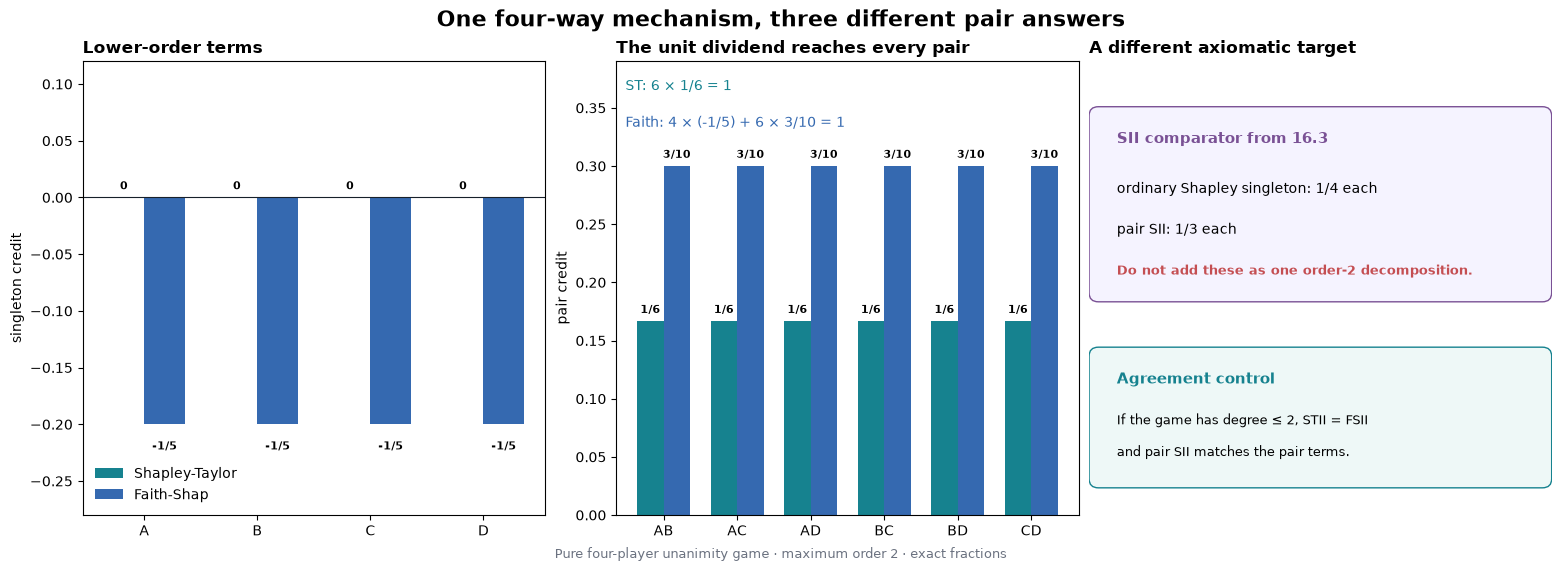

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/01_exact_allocation_ledger.png')

In [19]:
exact_diagnostics = diagnose_reconstruction(
    exact_diagnostics, reconstruct_game, faithfulness_error
)
figure = plot_exact_allocation_ledger(exact_diagnostics)
show_figure(figure, "01_exact_allocation_ledger")


The first figure keeps SII physically separate from the two efficient decompositions. Its singleton
and pair strips are valid indices, but adding them would manufacture a total that SII never claims.


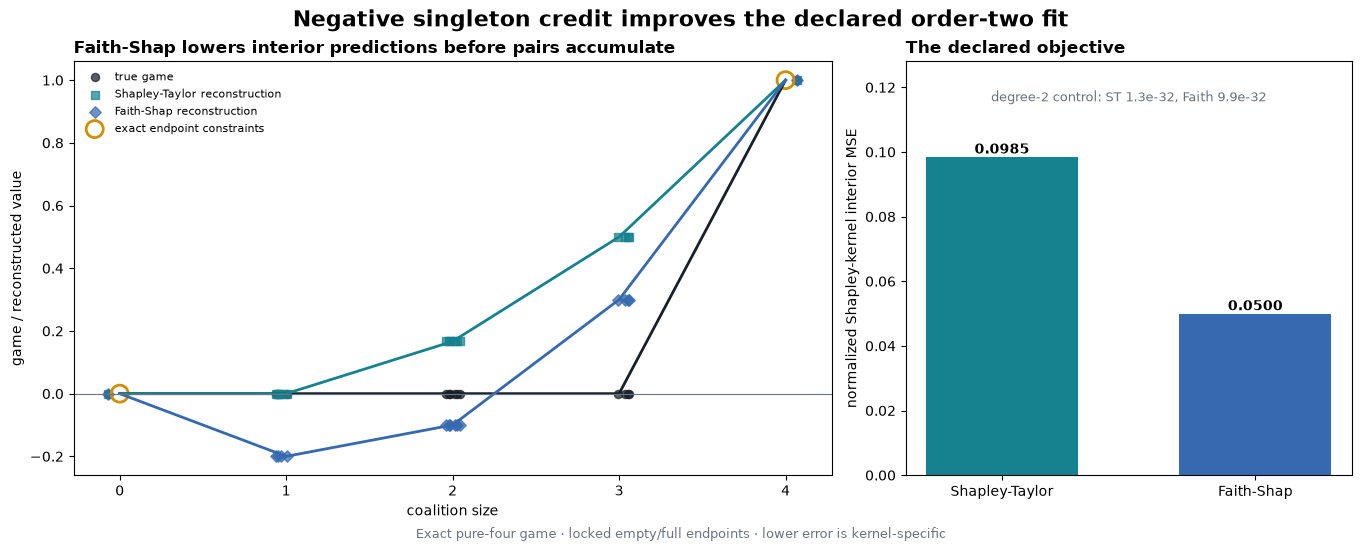

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/02_why_faith_moves_singletons.png')

In [20]:
figure = plot_reconstruction_reason(exact_diagnostics)
show_figure(figure, "02_why_faith_moves_singletons")


For the pure four-way table, Shapley-Taylor reconstructs coalition-size means
`[0, 0, 1/6, 1/2, 1]`; Faith-Shap reconstructs `[0, -1/5, -1/10, 3/10, 1]`.
The negative singleton is doing visible approximation work on the interior coalitions.


# 5️⃣ From a model to a complete finite game


## Intact donors define the missing-feature operation

For a scalar model $f$, query $x$, donor row $z_b$, and coalition $S$, define the hybrid

$$
h_i(x,z_b,S)=\begin{cases}x_i&i\in S\\z_{b,i}&i\notin S,\end{cases}
$$

and the finite-background game

$$
v_{x,B}(S)=\frac{1}{|B|}\sum_{b\in B}f(h(x,z_b,S)).
$$

All absent features come from the **same intact donor row**. Sampling each missing coordinate from a
different marginal would define a different game. The empty value is the donor-bank mean prediction;
the full value is the query prediction.

For example, with query `(10, 20, 30)`, donor `(1, 2, 3)`, and mask `101`, the hybrid is
`(10, 2, 30)`: the middle coordinate comes from that same donor. A second donor produces a second
complete hybrid, and only then do we average their model outputs.


### Exercise 7 - implement `masked_model_game`

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 20 minutes on this exercise.
> ```

Your scientific task is the intact hybrid and donor average. The supplied
`_interaction_game_batches` context validates inputs, preserves model state, and
enumerates the row × coalition × donor grid in bounded chunks. It yields the
number of rows, coalitions, and donors, followed by an iterator of batches.
Each batch gives you `query_rows`, `donor_rows`, `present`, and `slots`.

Use the first three arrays to build the hybrids with `torch.where`. Evaluate the
model through `_interaction_model_output`, accumulate its predictions into the
row/coalition `slots`, and divide each accumulated sum by the donor count.
You implement the missing-feature operation and its expectation; the supplied
context handles chunk indices and restores model/RNG state on exit.


In [21]:
def masked_model_game(
    model: nn.Module,
    x: Tensor,
    reference: Tensor,
    *,
    coalition_batch_size: int = 4096,
) -> Tensor:
    """Return games using one reference [D] or an equal-weight bank [B,D]."""
    with _interaction_game_batches(
        model, x, reference, coalition_batch_size=coalition_batch_size
    ) as (rows, coalitions, donors, batches):
        sums = torch.zeros(rows * coalitions, dtype=torch.float64)
        for query_rows, donor_rows, present, slots in batches:
            inputs = torch.where(present, query_rows, donor_rows)
            output = _interaction_model_output(model, inputs)
            sums.index_add_(0, slots, output)
        return sums.div(donors).reshape(rows, coalitions).detach()



tests.test_masked_model_game(fn=masked_model_game)


All tests in test_masked_model_game passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_masked_model_game passed!
```

The two-row, three-feature linear fixture returns shape `(2,8)`. Mask zero equals the mean donor
prediction, mask seven equals each query prediction, and all Möbius terms above order one are zero to
`1e-15`. RNG state, default dtype, module modes, buffers, and parameter gradients are restored on
successful and failing forwards.

</details>


<details>
<summary>Help - construct one intact hybrid</summary>

The three input arrays in a batch have the same `[batch, features]` shape. Use
`torch.where(present, query_rows, donor_rows)`. A false entry selects from the
matching donor row; it never selects a different donor independently per feature.
Check the mask `101` example above before thinking about the accumulation.

</details>


<details>
<summary>Help - turn donor predictions into a complete game</summary>

Several predictions belong to each row/coalition slot: one per donor. Accumulate
with `sums.index_add_(0, slots, output)` so a chunk boundary cannot discard part
of a donor average. After consuming all batches, divide by `donors` and reshape
to `(rows, coalitions)`. Dividing by the chunk size would be wrong: the final
chunk can be shorter, and a slot can span two chunks.

</details>


<details>
<summary>Interpretation</summary>

What changes when you switch from one donor to a 64-row donor bank?

The explanation game changes from one reference recipe to an equal-weight empirical population. The
new interaction is not a confidence replicate of the old one; it answers a different finite-game
question.

</details>


In [22]:
class _AdditiveDiagnosticModel(nn.Module):
    def forward(self, inputs: Tensor) -> Tensor:
        return 1.0 + 0.5 * inputs[:, 0] + 0.25 * inputs[:, 1].square() + torch.relu(inputs[:, 2])

def _additive_formula(inputs: Tensor) -> Tensor:
    return 1.0 + 0.5 * inputs[..., 0] + 0.25 * inputs[..., 1].square() + torch.relu(inputs[..., 2])

def diagnose_model_game(masked_model_game_fn: Callable[..., Tensor]) -> dict[str, Any]:
    """Exercise one donor-averaged model game with an additive nonlinear control."""

    _callable("masked_model_game_fn", masked_model_game_fn)
    model = _AdditiveDiagnosticModel().to(dtype=torch.float64)
    query = torch.tensor([[2.0, -1.0, 0.5]], dtype=torch.float64)
    donors = torch.tensor([[0.0, 0.0, -1.0], [1.0, -2.0, 1.0]], dtype=torch.float64)
    observed = masked_model_game_fn(model, query, donors, coalition_batch_size=3)
    masks = torch.arange(8, dtype=torch.int64)
    present = masks[:, None].bitwise_and(1 << torch.arange(3, dtype=torch.int64)).ne(0)
    hybrid = torch.where(present[:, None, :], query[:, None, :], donors[None, :, :])
    expected = _additive_formula(hybrid).mean(dim=1).unsqueeze(0)
    torch.testing.assert_close(observed, expected, rtol=0, atol=1e-12)
    mobius = observed.clone()
    for player in range(3):
        selected = masks.bitwise_and(1 << player).ne(0)
        mobius[..., selected] -= mobius[..., masks[selected].bitwise_xor(1 << player)]
    pair_masks = torch.tensor([3, 5, 6], dtype=torch.int64)
    torch.testing.assert_close(mobius[..., pair_masks], torch.zeros((1, 3), dtype=torch.float64), rtol=0, atol=1e-12)
    return {
        "evidence_kind": "analytic_exact",
        "label": "nonlinear additive donor-game control",
        "feature_names": ("linear", "square", "ReLU"),
        "query": query,
        "donors": donors,
        "game_values": observed,
        "expected_game_values": expected,
        "mobius": mobius,
        "pair_max_abs": float(mobius[..., pair_masks].abs().max().item()),
        "units": "fixture output units",
    }


In [23]:
model_game_diagnostic = diagnose_model_game(masked_model_game)
print("max |pair Möbius term|:", model_game_diagnostic["pair_max_abs"])


max |pair Möbius term|: 0.0


## A pair derivative opens four coalition values

For a pair $\{i,j\}$ disjoint from context $T$,

$$
\Delta_{ij}v(T)=v(T\cup\{i,j\})-v(T\cup\{i\})-v(T\cup\{j\})+v(T).
$$

This quantity may change sign across contexts. Shapley-Taylor, Faith-Shap, and SII aggregate
higher-order structure differently; none is required to equal the derivative at the empty or full
context.


### Exercise 8 - implement `contextual_pair_synergy`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend up to 15 minutes on this exercise.
> ```

Validate the pair, generate every disjoint context when none is supplied, or validate and sort the
provided contexts. Index the four masks without a Python loop over leading batch items.


In [24]:
def contextual_pair_synergy(
    game_values: Tensor,
    pair: tuple[int, int],
    *,
    n_players: int,
    context_masks: Tensor | None = None,
) -> tuple[Tensor, Tensor]:
    """Return sorted valid context masks and Delta_pair v(context)."""
    n_players = _interaction_n_players(n_players, minimum=2)
    _interaction_tensor("game_values", game_values, n_players)
    if (
        type(pair) is not tuple
        or len(pair) != 2
        or any(type(player) is not int for player in pair)
    ):
        raise TypeError("pair must contain exactly two integer player indices.")
    first, second = pair
    if first == second:
        raise ValueError("pair must contain two different players.")
    if not 0 <= first < n_players or not 0 <= second < n_players:
        raise ValueError("pair players must lie in [0, n_players).")
    pair_mask = (1 << first) | (1 << second)

    if context_masks is None:
        contexts = torch.tensor(
            [
                mask
                for mask in range(2**n_players)
                if mask & pair_mask == 0
            ],
            dtype=torch.int64,
        )
    else:
        if type(context_masks) is not Tensor:
            raise TypeError("context_masks must be a torch.Tensor.")
        if context_masks.device.type != "cpu" or context_masks.dtype != torch.int64:
            raise TypeError("context_masks must be a CPU int64 tensor.")
        if context_masks.ndim != 1 or context_masks.numel() == 0:
            raise ValueError("context_masks must be a nonempty one-dimensional tensor.")
        if context_masks.min() < 0 or context_masks.max() >= 2**n_players:
            raise ValueError("Every context mask must index the complete game.")
        if context_masks.bitwise_and(pair_mask).ne(0).any():
            raise ValueError("Context masks must be disjoint from the requested pair.")
        contexts = context_masks.sort().values

    with_first = contexts.bitwise_or(1 << first)
    with_second = contexts.bitwise_or(1 << second)
    with_pair = contexts.bitwise_or(pair_mask)
    synergy = (
        game_values[..., with_pair]
        - game_values[..., with_first]
        - game_values[..., with_second]
        + game_values[..., contexts]
    )
    return contexts, synergy



tests.test_contextual_pair_synergy(fn=contextual_pair_synergy)


All tests in test_contextual_pair_synergy passed!


<details>
<summary>Expected output</summary>

```text
All tests in test_contextual_pair_synergy passed!
```

For a three-player game with pair dividend `2` and triple dividend `3`, pair `(0,1)` has contexts
`[0,4]` and signed derivatives `[2,5]`. A leading batch scaled by `-2` returns `[-4,-10]`.

</details>


<details>
<summary>Help - build the pair mask once</summary>

Set `pair_mask = (1 << first) | (1 << second)`. Valid contexts satisfy
`context & pair_mask == 0`. The four lookup axes are context, context plus the first bit, context
plus the second bit, and context plus both bits.

</details>


<details>
<summary>Interpretation</summary>

Why does an independently re-run four-forward check matter if the complete game table already
contains these values?

It catches a wrong mask convention or second-difference sign in the stored table lookup. Agreement
is an implementation control. It does not turn the replacement into a physical intervention.

</details>


In [25]:
def diagnose_pair_context(contextual_pair_synergy_fn: Callable[..., tuple[Tensor, Tensor]]) -> dict[str, Any]:
    """Show where a pure triple's pair derivative switches on."""

    _callable("contextual_pair_synergy_fn", contextual_pair_synergy_fn)
    fixture = exact_game_fixture()
    game = fixture["game_values"][GAME_NAMES.index("pure_triple")]
    contexts, synergy = contextual_pair_synergy_fn(game, (0, 1), n_players=4)
    expected_contexts = torch.tensor([0, 4, 8, 12], dtype=torch.int64)
    expected_synergy = torch.tensor([0.0, 1.0, 0.0, 1.0], dtype=torch.float64)
    torch.testing.assert_close(contexts, expected_contexts, rtol=0, atol=0)
    torch.testing.assert_close(synergy, expected_synergy, rtol=0, atol=1e-12)
    full_context = 12
    four_masks = torch.tensor([full_context, full_context | 1, full_context | 2, full_context | 3], dtype=torch.int64)
    return {
        "evidence_kind": "analytic_exact",
        "label": "pure-triple contextual pair diagnostic",
        "pair": (0, 1),
        "contexts": contexts,
        "synergy": synergy,
        "full_context_mask": full_context,
        "four_masks": four_masks,
        "four_values": game[four_masks],
        "pair_sii": float(fixture["sii_pairs"][GAME_NAMES.index("pure_triple"), 0].item()),
    }


In [26]:
pair_context_diagnostic = diagnose_pair_context(contextual_pair_synergy)
print("contexts:", pair_context_diagnostic["contexts"].tolist())
print("pair derivatives:", pair_context_diagnostic["synergy"].tolist())


contexts: [0, 4, 8, 12]
pair derivatives: [0.0, 1.0, 0.0, 1.0]


In [27]:
methods = SimpleNamespace(
    mobius_transform=mobius_transform,
    shapley_taylor_interactions=shapley_taylor_interactions,
    faith_design_matrix=faith_design_matrix,
    faith_kernel_weights=faith_kernel_weights,
    faith_shap_interactions=faith_shap_interactions,
    faith_shap_closed_form=faith_shap_closed_form,
    reconstruct_game=reconstruct_game,
    faithfulness_error=faithfulness_error,
    masked_model_game=masked_model_game,
    contextual_pair_synergy=contextual_pair_synergy,
)


## Try It Yourself: reroute a dividend

This exact play is available before any native fit. Change `PLAY_MEMBERS`, `PLAY_VALUE`, or
`PLAY_ORDER`, then predict the allocation before running it. Try a pure triple at order two, and then
set the retained order equal to the dividend degree.


In [28]:
PLAY_N = 4
PLAY_MEMBERS = (0, 1, 2, 3)
PLAY_VALUE = 1.0
PLAY_ORDER = 2

dividend_play = exact_dividend_play(
    methods=methods,
    n_players=PLAY_N,
    members=PLAY_MEMBERS,
    value=PLAY_VALUE,
    order=PLAY_ORDER,
)
explained_play = dividend_play["explained"]
retained_masks = [
    mask for mask in range(1, 2**PLAY_N) if mask.bit_count() <= PLAY_ORDER
]
for label, values in (
    ("Shapley-Taylor", explained_play["stii_coefficients"]),
    ("Faith-Shap", explained_play["fsii_coefficients"]),
):
    nonzero = {
        f"{mask:0{PLAY_N}b}": round(float(values[mask]), 6)
        for mask in retained_masks
        if abs(float(values[mask])) > 1e-12
    }
    print(f"{label:15s}", nonzero)


Shapley-Taylor  {'0011': 0.166667, '0101': 0.166667, '0110': 0.166667, '1001': 0.166667, '1010': 0.166667, '1100': 0.166667}
Faith-Shap      {'0001': -0.2, '0010': -0.2, '0011': 0.3, '0100': -0.2, '0101': 0.3, '0110': 0.3, '1000': -0.2, '1001': 0.3, '1010': 0.3, '1100': 0.3}


<details>
<summary>Ideas to try</summary>

1. Use `PLAY_MEMBERS=(0,1,2)`: predict Shapley-Taylor `0, 1/3` and Faith-Shap
   `-1/6, 1/2` for contained singletons and pairs.
2. Use a negative value. Every method should change sign without changing its allocation fractions.
3. Use `PLAY_ORDER=len(PLAY_MEMBERS)`. Both efficient methods should recover the literal Möbius
   dividend rather than route it downward.

</details>


## Plot the dividend you chose

The earlier exact play remains in memory. This figure places its Shapley-Taylor, Faith-Shap, and SII
allocations beside the same-game reconstruction errors.


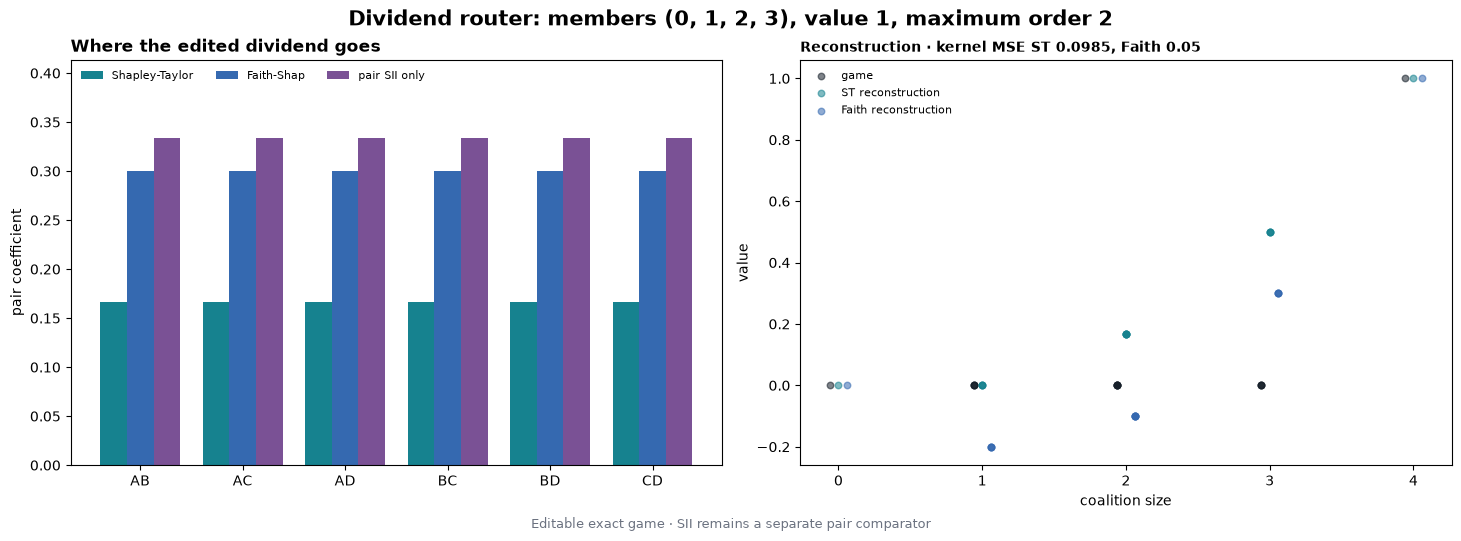

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/10_dividend_play.png')

In [29]:
figure = plot_dividend_play(dividend_play)
show_figure(figure, "10_dividend_play")


# 6️⃣ Guided native capstone: the same game, different allocation rules


## The finite Concrete replacement game

The native study reuses the known UCI Concrete split and predictor recipe from 16.14/16.15 so that
the interaction definition is the variable:

- eight input features and raw compressive-strength output in MPa;
- 758 training rows, 153 explanation rows, and 119 audit rows in disjoint recipe groups;
- three clean ReLU MLP seeds, three matched shuffled-target controls, and ridge;
- all seven models, all 272 held-out rows, all 256 masks, and the ordered primary bank of 64 intact
  training donors; and
- order-two Shapley-Taylor, Faith-Shap, and pair SII on the same complete games.

Five background designs are retained for `clean_0`; each defines a different finite game. Ridge is
the additive control. Shuffled-target models are predictive controls, not zero-interaction oracles.

The path is: **fit the seven models → build their complete games → compare the allocations**.
You already wrote the scientific operations. The supplied study runners below apply them consistently;
their code is expandable in JupyterLab and on the instruction page. Open and edit it whenever you want
to trace a calculation. The short calling cells remain the main path.

This is a self-contained reproduction of a known seeded model/data procedure, not an independent
model or dataset replication.


<details>
<summary>Question - why retain donor-level predictions after averaging the game?</summary>

The average alone cannot prove that every absent feature came from one intact row. Donor-level
predictions preserve that construction and let the editable microscope show signed cancellation
across real donor recipes.

</details>


## Independent exact-game reference adapter

The primary-paper and `shapiq` comparisons are supporting evidence rather than another student
method. Their small-game checks run during preparation; the exhaustive 2,992-game empirical check
runs once after evaluation. The wrapper is visible so the learner can see exactly which arrays and
scope enter the benchmark.


In [30]:
def reference_check(
    game_values: np.ndarray | torch.Tensor,
    student_stii: np.ndarray | torch.Tensor,
    student_fsii: np.ndarray | torch.Tensor,
    student_sii_pairs: np.ndarray | torch.Tensor,
    *,
    n_players: int,
    order: int,
    expected_game_count: int | None = None,
) -> dict[str, Any]:
    """Validate every supplied complete game with independent and direct package references."""

    with _preserve_execution_state():
        return _reference_check_impl(
            game_values,
            student_stii,
            student_fsii,
            student_sii_pairs,
            n_players=n_players,
            order=order,
            expected_game_count=expected_game_count,
        )

def validate_exact_reference_suite(prepared: Mapping[str, Any]) -> dict[str, Any]:
    """Revalidate the retained 8 fixed, 45 random-order, and 5 boundary cases."""

    with _preserve_execution_state():
        if not isinstance(prepared, Mapping) or prepared.get("phase") != "prepared_before_audit":
            raise ValueError("prepared must be the sealed pre-audit study payload.")
        return _validate_exact_suite(prepared)

def finalize_study_reference(
    prepared: Mapping[str, Any], empirical_reference: Mapping[str, Any]
) -> dict[str, Any]:
    """Validate and augment an existing all-2,992 empirical result without package calls."""

    with _preserve_execution_state():
        payload_validation = validate_reference_payload(
            empirical_reference, expected_game_count=2_992
        )
        exact_validation = validate_exact_reference_suite(prepared)
        result = dict(empirical_reference)
        result["counts"] = dict(empirical_reference["counts"])
        result["exact_suite_validation"] = exact_validation
        result["payload_validation"] = payload_validation
        result["counts"].update(
            {
                "primary_games": 1_904,
                "nonprimary_clean0_games": 1_088,
                "models": 7,
                "rows_per_model": 272,
                "background_variants": 4,
                "fixed_unique_exact_games": exact_validation["fixed_unique_games"],
                "random_unique_exact_games": exact_validation["random_unique_games"],
                "random_game_order_cases": exact_validation[
                    "random_game_order_cases"
                ],
                "random_STII_plus_FSII_case_calls": exact_validation[
                    "random_STII_plus_FSII_case_calls"
                ],
                "boundary_order_n_cases": exact_validation[
                    "boundary_order_n_cases"
                ],
                "exact_direct_shapiq_exact_computers": exact_validation[
                    "direct_shapiq_exact_computers"
                ],
                "exact_direct_shapiq_index_calls": exact_validation[
                    "direct_shapiq_index_calls"
                ],
                "all_reference_direct_shapiq_exact_computers": (
                    2_992 + exact_validation["direct_shapiq_exact_computers"]
                ),
                "all_reference_direct_shapiq_index_calls": (
                    2_992 * 3 + exact_validation["direct_shapiq_index_calls"]
                ),
                "all_reference_student_full_axis_coordinates": (
                    result["counts"]["student_full_axis_coordinates"]
                    + exact_validation["student_full_axis_coordinates"]
                ),
                "all_reference_independent_vs_package_relevant_coordinates": (
                    result["counts"]["independent_vs_package_relevant_coordinates"]
                    + exact_validation[
                        "independent_vs_package_relevant_coordinates"
                    ]
                ),
                "all_reference_raw_package_returned_coordinates": (
                    result["counts"]["raw_package_returned_coordinates"]
                    + exact_validation["raw_package_returned_coordinates"]
                ),
            }
        )
        if (
            result.get("status") != "PASS"
            or result["counts"]["all_reference_direct_shapiq_exact_computers"]
            != 3_050
            or result["counts"]["all_reference_direct_shapiq_index_calls"] != 9_150
        ):
            raise AssertionError("The complete exact plus empirical reference scope is invalid.")
        return result


In [31]:
reference_methods = SimpleNamespace(reference_check=reference_check)


## The preparation boundary

We use explanation rows to choose the pair order, then measure it once on separate audit rows.
This keeps the held-out comparison useful even when the explanation rankings look surprising.

<details>
<summary>How leakage is prevented, and what is retained</summary>

Training, exact fixtures, primary explanation games, method outputs, and complete explanation-side
pair orders are fixed and persisted before audit access. The local display defaults are content-blind:
`clean_0`, explanation source ID `0`, pair `(0,1)`, primary donor ID `173`, and full context mask
`252`. No audit value chooses a model, row, pair, donor, background, tolerance, or plot.

The primary donor predictions have logical shape `[7,272,256,64]`; averaging the last axis produces
1,904 complete games. Explanation and audit donor predictions are stored in separate physical files,
and the explanation files are sealed before loading the audit split. Four additional background
games per row retain their own donor predictions. Full method outputs, reference comparisons, and
controls stay available in the evidence, including signs, zero denominators, and unfavorable results.

The execution cell checks the frozen protocol and recorded review disposition before loading data or
fitting a model. A development run with independent review still pending cannot be published as a
completed section. [The protocol](protocol.md) records the full counts, seeds, and acceptance rules.

</details>


In [32]:
FEATURES = 8

HIDDEN = 32

EMPIRICAL_ORDER = 2

TRAINING_STEPS = 800

LEARNING_RATE = 0.003

WEIGHT_DECAY = 0.0001

RIDGE_PENALTY = 0.01

FORWARD_BATCH = 32_768

DISTANCE_BATCH = 2_048

MODEL_KEYS = (
    "clean_0",
    "clean_1",
    "clean_2",
    "shuffled_0",
    "shuffled_1",
    "shuffled_2",
    "ridge",
)

MODEL_SEEDS = (161410, 161411, 161412)

SHUFFLE_SEEDS = (161420, 161421, 161422)

BACKGROUND_SPECS = {
    "primary64": (161460, 64),
    "nested16": (161460, 16),
    "nested128": (161460, 128),
    "independent64_a": (161461, 64),
    "independent64_b": (161462, 64),
}

METHOD_KEYS = ("sii", "stii", "fsii")

METHOD_NAMES = (
    "mobius_transform",
    "shapley_taylor_interactions",
    "faith_design_matrix",
    "faith_kernel_weights",
    "faith_shap_interactions",
    "faith_shap_closed_form",
    "reconstruct_game",
    "faithfulness_error",
    "masked_model_game",
    "contextual_pair_synergy",
)

FEATURE_NAMES = (
    "Cement",
    "Slag",
    "Fly ash",
    "Water",
    "Superplasticizer",
    "Coarse aggregate",
    "Fine aggregate",
    "Age",
)

FEATURE_UNITS = ("kg/m3",) * 7 + ("days",)

TARGET_NAME = "Compressive strength"

TARGET_UNIT = "MPa"

RNG_NAMESPACE = "arena16.16/shapley-interactions/v1"

RANDOM_EXACT_SEED = 161610

WITHIN_SIZE_SEED = 161611

RANDOM_PAIR_SEED = 161612

WITHIN_SIZE_REPLICATES = 128

RANDOM_PAIR_ORDERS = 256

SUPPORT_DONORS = 8

DEFAULT_PLAY = {
    "model_key": "clean_0",
    "source_id": 0,
    "donor_source_id": 173,
    "background_key": "primary64",
    "pair": (0, 1),
    "context_mask": 252,
}


The next visible source group contains the known-model training recipe, raw-unit folding, and exact
21-state reproduction gate. A mismatch stops before any interaction game is constructed.


In [33]:
def _train_mlp(
    model: t.nn.Sequential, x: t.Tensor, y: t.Tensor
) -> tuple[dict[str, t.Tensor], t.Tensor]:
    """Run the visible fixed 800-step full-batch Adam training loop."""

    optimizer = t.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    losses = []
    model.train()
    for _ in range(TRAINING_STEPS):
        optimizer.zero_grad()
        loss = (model(x).squeeze(-1) - y).square().mean()
        loss.backward()
        optimizer.step()
        losses.append(loss.detach().clone())
    return _clone_state(model.state_dict()), t.stack(losses)

def fit_known_models(train: Mapping[str, Any]) -> dict[str, Any]:
    """Reproduce all seven known predictors; callers enforce the freeze gate."""

    x, y, ids, groups = _rows(train, "train")
    t.set_num_threads(4)
    t.use_deterministic_algorithms(True)
    normalization = _training_normalization(train)
    models: dict[str, Any] = {}
    for index, seed in enumerate(MODEL_SEEDS):
        models[f"clean_{index}"] = _fit_one_mlp(train, normalization, seed, None)
    for index, seed in enumerate(MODEL_SEEDS):
        models[f"shuffled_{index}"] = _fit_one_mlp(
            train, normalization, seed, SHUFFLE_SEEDS[index]
        )
    models["ridge"] = _fit_ridge(train, normalization)
    for record in models.values():
        record["state_hashes"] = {
            "initial_state": tensor_mapping_sha256(record["initial_state"]),
            "standardized_state": tensor_mapping_sha256(record["standardized_state"]),
            "raw_folded_state": tensor_mapping_sha256(record["state"]),
        }
    return {
        "phase": "fitted_before_interactions",
        "models": models,
        "normalization": normalization,
        "train_x_raw": x.clone(),
        "train_y_raw": y.clone(),
        "train_ids": ids.clone(),
        "train_recipe_group_ids": groups.clone(),
        "feature_names": FEATURE_NAMES,
        "feature_units": FEATURE_UNITS,
        "target_name": TARGET_NAME,
        "target_unit": TARGET_UNIT,
    }

def verify_known_reproduction(
    fitted: Mapping[str, Any], manifest: Mapping[str, Any]
) -> dict[str, Any]:
    """Hard-fail unless all 21 known state hashes and fit identities agree."""

    _validate_fitted(fitted)
    expected = manifest.get("known_16_14_evidence", {}).get("model_state_hashes", {})
    if tuple(expected) != MODEL_KEYS:
        raise ValueError("Manifest must declare all seven known model hashes.")
    fields = {
        "initial_state": "initial_state",
        "standardized_state": "standardized_state",
        "raw_folded_state": "state",
    }
    observed: dict[str, dict[str, str]] = {}
    mismatches: list[str] = []
    for key in MODEL_KEYS:
        record = fitted["models"][key]
        observed[key] = {
            label: tensor_mapping_sha256(record[field]) for label, field in fields.items()
        }
        for label in fields:
            if observed[key][label] != expected[key][label]:
                mismatches.append(f"{key}.{label}")
        if record.get("state_hashes") != observed[key]:
            mismatches.append(f"{key}.retained_state_hashes")
    train_ids = t.tensor(manifest.get("splits", {}).get("train", []), dtype=t.int64)
    if not t.equal(train_ids, fitted["train_ids"]):
        mismatches.append("train_ids")
    recipe = manifest.get("model_recipe", {})
    recipe_matches = (
        recipe.get("model_keys") == list(MODEL_KEYS)
        and recipe.get("model_seeds") == list(MODEL_SEEDS)
        and recipe.get("shuffle_seeds") == list(SHUFFLE_SEEDS)
        and recipe.get("training_steps") == TRAINING_STEPS
        and recipe.get("learning_rate") == LEARNING_RATE
        and recipe.get("weight_decay") == WEIGHT_DECAY
        and recipe.get("ridge_penalty") == RIDGE_PENALTY
    )
    if not recipe_matches:
        mismatches.append("training_recipe")
    if mismatches:
        raise AssertionError("Known-model reproduction mismatch: " + ", ".join(mismatches))
    return {
        "status": "PASS",
        "known_section": "16.14/16.15",
        "model_state_hashes": observed,
        "expected_model_state_hashes": expected,
        "mismatches": (),
        "state_comparisons": 21,
        "training_recipe_match": True,
        "train_ids_match": True,
        "non_independent_replication": True,
    }


In [34]:
freeze = validate_freeze()
manifest = load_manifest()
train = load_split("train")
explain = load_split("explain")


Before fitting, look at the actual replacement operation. The table uses the fixed explanation recipe
and donor. Mask `11111100` keeps the other six features from the query while replacing cement and
slag from the donor. These are the context values for the pair examined later.


In [35]:
query_row = explain["x"][np.flatnonzero(explain["ids"] == 0).item()]
donor_row = train["x"][np.flatnonzero(train["ids"] == 173).item()]
preview_present = (252 & (1 << np.arange(8))) != 0
display(pd.DataFrame({
    "feature": FEATURE_NAMES,
    "unit": FEATURE_UNITS,
    "query (source 0)": query_row,
    "donor (source 173)": donor_row,
    "hybrid 11111100": np.where(preview_present, query_row, donor_row),
    "taken from": np.where(preview_present, "query", "donor"),
}).set_index("feature"))


,unit,query (source 0),donor (source 173),hybrid 11111100,taken from
feature,,,,,
Cement,kg/m3,540.0,318.8,318.8,donor
Slag,kg/m3,0.0,212.5,212.5,donor
Fly ash,kg/m3,0.0,0.0,0.0,query
Water,kg/m3,162.0,155.7,162.0,query
Superplasticizer,kg/m3,2.5,14.3,2.5,query
Coarse aggregate,kg/m3,1040.0,852.1,1040.0,query
Fine aggregate,kg/m3,676.0,880.4,676.0,query
Age,days,28.0,91.0,28.0,query


In [36]:
fitted = fit_known_models(train)
reproduction = verify_known_reproduction(fitted, manifest)
fitted = {**fitted, "reproduction": reproduction}
print(f"All {reproduction['state_comparisons']} known model-state comparisons passed.")


All 21 known model-state comparisons passed.


The hybrid builder below retains each donor prediction before its equal-weight mean. Its batch size
is an engineering control only; it never changes the masks, rows, donors, models, or values.


In [37]:
def donor_replacement_games(
    model: t.nn.Module,
    queries: t.Tensor,
    donors: t.Tensor,
    *,
    methods: Any,
    donor_source_ids: t.Tensor | None = None,
    coalition_batch_size: int = 4096,
) -> dict[str, t.Tensor]:
    """Retain every single-donor game, then average the declared donor bank."""

    _require_methods(methods)
    x = _float_tensor(queries, "queries", 2)
    background = _float_tensor(donors, "donors", 2)
    if x.shape[1] != FEATURES or background.shape[1] != FEATURES or len(background) == 0:
        raise ValueError("queries and donors must contain eight-feature rows.")
    if not isinstance(coalition_batch_size, int) or coalition_batch_size <= 0:
        raise ValueError("coalition_batch_size must be positive.")
    if donor_source_ids is None:
        donor_source_ids = t.arange(len(background), dtype=t.int64)
    donor_source_ids = _int_tensor(donor_source_ids, "donor_source_ids", 1)
    if donor_source_ids.shape != (len(background),) or len(t.unique(donor_source_ids)) != len(background):
        raise ValueError("donor_source_ids must uniquely identify every donor.")
    hybrid = t.empty((len(x), 2**FEATURES, len(background)), dtype=t.float64)
    for donor_index, donor in enumerate(background):
        game = methods.masked_model_game(
            model, x, donor, coalition_batch_size=coalition_batch_size
        )
        game = _float_tensor(game, "single_donor_game", 2)
        if game.shape != (len(x), 2**FEATURES):
            raise ValueError("masked_model_game returned an unexpected shape.")
        hybrid[..., donor_index] = game
    return {
        "hybrid_prediction": hybrid,
        "coalition_values": hybrid.mean(-1),
        "donor_source_ids": donor_source_ids.clone(),
    }

def evaluate_model_games(
    model: t.nn.Module,
    queries: t.Tensor,
    donors: t.Tensor,
    *,
    methods: Any,
    donor_source_ids: t.Tensor,
    coalition_batch_size: int = 4096,
) -> dict[str, t.Tensor]:
    """Construct one retained donor game and compute every exact order-two output."""

    donor = donor_replacement_games(
        model,
        queries,
        donors,
        methods=methods,
        donor_source_ids=donor_source_ids,
        coalition_batch_size=coalition_batch_size,
    )
    explained = explain_complete_games(donor["coalition_values"], methods=methods)
    return {**donor, **explained}


The exact-game block applies your ten functions to the fixed pure and mixed controls. Pair SII is a
separate transparent comparator. It is never concatenated with singleton Shapley values to create a
fake efficient decomposition.


In [38]:
def pairwise_sii(game_values: t.Tensor, *, n_players: int) -> t.Tensor:
    """Compute the exact pair SII comparator in lexicographic pair order."""

    values = _float_tensor(game_values, "game_values")
    if values.ndim < 1 or values.shape[-1] != 2**n_players or n_players < 2:
        raise ValueError("game_values must end in one complete game axis.")
    output = []
    for left, right in pair_indices(n_players).tolist():
        pair_mask = (1 << left) | (1 << right)
        contexts = [
            mask for mask in range(2**n_players) if mask & pair_mask == 0
        ]
        score = t.zeros(values.shape[:-1], dtype=t.float64)
        denominator = math.factorial(n_players - 1)
        for context in contexts:
            size = int(context).bit_count()
            weight = (
                math.factorial(size)
                * math.factorial(n_players - size - 2)
                / denominator
            )
            delta = (
                values[..., context | pair_mask]
                - values[..., context | (1 << left)]
                - values[..., context | (1 << right)]
                + values[..., context]
            )
            score = score + weight * delta
        output.append(score)
    return t.stack(output, dim=-1)

def all_pair_context_synergies(
    game_values: t.Tensor, *, n_players: int, methods: Any
) -> dict[str, t.Tensor]:
    """Apply the learner's local derivative to all pairs and valid contexts."""

    _require_methods(methods)
    values = _float_tensor(game_values, "game_values")
    pairs = pair_indices(n_players)
    context_rows = []
    synergy_rows = []
    full_rows = []
    for left, right in pairs.tolist():
        contexts, synergy = methods.contextual_pair_synergy(
            values, (left, right), n_players=n_players
        )
        contexts = _int_tensor(contexts, "context_masks", 1)
        synergy = _float_tensor(synergy, "context_synergy")
        if synergy.shape != values.shape[:-1] + (len(contexts),):
            raise ValueError("contextual_pair_synergy returned an unexpected shape.")
        expected_full = (2**n_players - 1) ^ (1 << left) ^ (1 << right)
        positions = t.nonzero(contexts == expected_full).flatten()
        if len(positions) != 1:
            raise ValueError("The full pair context is absent or repeated.")
        context_rows.append(contexts)
        synergy_rows.append(synergy)
        full_rows.append(synergy[..., int(positions[0])])
    context_masks = t.stack(context_rows)
    context_synergy = t.stack(synergy_rows, dim=-2)
    return {
        "pair_indices": pairs,
        "context_masks": context_masks,
        "context_synergy": context_synergy,
        "full_context_synergy": t.stack(full_rows, dim=-1),
        "mean_abs_context_synergy": context_synergy.abs().mean(-1),
    }

def explain_complete_games(
    game_values: t.Tensor,
    *,
    methods: Any,
    n_players: int = FEATURES,
    order: int = EMPIRICAL_ORDER,
    include_contexts: bool = True,
) -> dict[str, t.Tensor]:
    """Apply every visible interaction method to a batch of complete games."""

    _require_methods(methods)
    values = _float_tensor(game_values, "game_values")
    if values.ndim < 1 or values.shape[-1] != 2**n_players:
        raise ValueError("game_values must end in one complete bitmask axis.")
    mobius = methods.mobius_transform(values, n_players=n_players)
    mobius = _float_tensor(mobius, "mobius")
    stii = methods.shapley_taylor_interactions(mobius, n_players=n_players, order=order)
    fsii = methods.faith_shap_interactions(values, n_players=n_players, max_order=order)
    closed = methods.faith_shap_closed_form(mobius, n_players=n_players, max_order=order)
    stii = _float_tensor(stii, "stii_coefficients")
    fsii = _float_tensor(fsii, "fsii_coefficients")
    closed = _float_tensor(closed, "fsii_closed_form")
    expected_shape = values.shape
    if stii.shape != expected_shape or fsii.shape != expected_shape or closed.shape != expected_shape:
        raise ValueError("Interaction coefficient tensors must preserve the game shape.")
    ordinary_full = methods.shapley_taylor_interactions(
        mobius, n_players=n_players, order=1
    )
    singleton_masks = 1 << t.arange(n_players, dtype=t.int64)
    pairs = pair_indices(n_players)
    pair_masks = (1 << pairs[:, 0]) | (1 << pairs[:, 1])
    sii = pairwise_sii(values, n_players=n_players)
    recon = t.stack(
        [
            methods.reconstruct_game(stii, n_players=n_players),
            methods.reconstruct_game(fsii, n_players=n_players),
        ]
    )
    recon = _float_tensor(recon, "reconstruction")
    residual = values.unsqueeze(0) - recon
    sizes = coalition_masks(n_players).sum(-1)
    rmse = t.stack(
        [
            t.sqrt(residual[..., sizes == size].square().mean(-1))
            for size in range(n_players + 1)
        ],
        dim=-1,
    )
    kernel_mse = t.stack(
        [
            methods.faithfulness_error(values, stii, n_players=n_players),
            methods.faithfulness_error(values, fsii, n_players=n_players),
        ]
    )
    result = {
        "coalition_values": values,
        "mobius": mobius,
        "ordinary_shapley": ordinary_full[..., singleton_masks],
        "sii_pairs": sii,
        "stii_coefficients": stii,
        "fsii_coefficients": fsii,
        "fsii_closed_form": closed,
        "fsii_closed_form_error": (fsii - closed).abs().amax(-1),
        "pair_values": t.stack([sii, stii[..., pair_masks], fsii[..., pair_masks]], dim=-2),
        "reconstruction": recon,
        "residual": residual,
        "kernel_mse": kernel_mse,
        "rmse_by_size": rmse,
        "efficiency_residual": t.stack(
            [stii.sum(-1) - values[..., -1], fsii.sum(-1) - values[..., -1]]
        ),
        "pair_indices": pairs,
        "pair_masks": pair_masks,
    }
    if include_contexts:
        result.update(all_pair_context_synergies(values, n_players=n_players, methods=methods))
    return result


The preparation source now computes the primary explanation games, all exact method outputs,
recipe-group-weighted pair strengths, and complete 28-pair orders. It seals the physical explanation
donor shard before the audit split is loaded.


In [39]:
def explanation_pair_rankings(
    pair_values: t.Tensor, recipe_group_ids: t.Tensor
) -> dict[str, t.Tensor]:
    """Rank all 28 pairs from explanation groups without dropping any pair."""

    values = _float_tensor(pair_values, "pair_values", 4)
    if values.shape[2:] != (len(METHOD_KEYS), math.comb(FEATURES, 2)):
        raise ValueError("pair_values must have shape [models, rows, 3, 28].")
    strengths = t.stack(
        [_group_weighted_mean_abs(model_values, recipe_group_ids) for model_values in values]
    )
    orders = t.argsort(strengths, dim=-1, descending=True, stable=True)
    return {"method_keys": METHOD_KEYS, "pair_strength": strengths, "pair_order": orders}

def fixed_random_pair_orders() -> dict[str, Any]:
    """Return all 256 content-independent random pair permutations."""

    orders = []
    seeds = []
    for replicate in range(RANDOM_PAIR_ORDERS):
        derived = _derived_seed(RANDOM_PAIR_SEED, replicate)
        seeds.append(derived)
        orders.append(np.random.Generator(np.random.PCG64(derived)).permutation(28))
    result = {
        "seed": RANDOM_PAIR_SEED,
        "derived_seeds_hex": tuple(f"{value:032x}" for value in seeds),
        "orders": t.tensor(np.stack(orders), dtype=t.int64),
    }
    declared = load_manifest().get("rng_contract", {}).get("random_pair_order", {})
    if declared.get("derived_seeds_hex") != list(result["derived_seeds_hex"]):
        raise ValueError("Random pair-order seeds differ from the manifest.")
    if declared.get("orders_value_sha256") != tensor_mapping_sha256(
        {"orders": result["orders"]}
    ):
        raise ValueError("Random pair orders differ from the manifest.")
    return result

def prepare_study(
    fitted: Mapping[str, Any],
    train: Mapping[str, Any],
    explain: Mapping[str, Any],
    *,
    methods: Any,
    reference: Any | None = None,
    manifest: Mapping[str, Any] | None = None,
) -> dict[str, Any]:
    """Compute and seal every explanation-side decision before audit access."""

    _require_methods(methods)
    manifest = load_manifest() if manifest is None else manifest
    reproduction = verify_known_reproduction(fitted, manifest)
    train_x, train_y, train_ids, train_groups = _rows(train, "train")
    explain_x, explain_y, explain_ids, explain_groups = _rows(explain, "explain")
    _require_disjoint_ids(train=train_ids, explain=explain_ids)
    if not t.equal(train_x, fitted["train_x_raw"]) or not t.equal(train_y, fitted["train_y_raw"]):
        raise ValueError("Training values changed after fitting.")
    if not t.equal(train_ids, fitted["train_ids"]) or not t.equal(train_groups, fitted["train_recipe_group_ids"]):
        raise ValueError("Training identities changed after fitting.")
    expected_explain = t.tensor(manifest.get("splits", {}).get("explain", []), dtype=t.int64)
    if not t.equal(explain_ids, expected_explain):
        raise ValueError("Explanation source IDs differ from the pinned split.")
    backgrounds = _background_records(train_x, train_ids, manifest)
    primary = _evaluate_primary(fitted, explain_x, backgrounds["primary64"], methods=methods)
    variants = _evaluate_backgrounds(
        fitted, explain_x, backgrounds, primary, methods=methods
    )
    rankings = explanation_pair_rankings(primary["pair_values"], explain_groups)
    direct = _direct_full_context_four(fitted, explain_x, backgrounds["primary64"]["x_raw"])
    direct["table_synergy"] = primary["full_context_synergy"]
    direct["lookup_difference"] = direct["synergy"] - direct["table_synergy"]
    design_contract = {}
    for order in (1, 2, 3):
        design, term_masks = methods.faith_design_matrix(
            n_players=FEATURES, max_order=order
        )
        design_contract[order] = {
            "design": _float_tensor(design, f"faith_design_{order}", 2),
            "term_masks": _int_tensor(term_masks, f"term_masks_{order}", 1),
        }
    design_contract["kernel_weights"] = _float_tensor(
        methods.faith_kernel_weights(n_players=FEATURES), "kernel_weights", 1
    )
    return {
        "phase": "prepared_before_audit",
        "audit_used_for_selection": False,
        "reproduction": reproduction,
        "feature_names": FEATURE_NAMES,
        "feature_units": FEATURE_UNITS,
        "target_name": TARGET_NAME,
        "target_unit": TARGET_UNIT,
        "model_keys": MODEL_KEYS,
        "method_keys": METHOD_KEYS,
        "mask_ids": t.arange(2**FEATURES, dtype=t.int64),
        "coalition_masks": coalition_masks(FEATURES),
        "coalition_sizes": coalition_masks(FEATURES).sum(-1).to(t.int64),
        "pair_indices": pair_indices(FEATURES),
        "context_masks": primary["context_masks"],
        "design_contract": design_contract,
        "train_ids": train_ids,
        "train_recipe_group_ids": train_groups,
        "explain_source_ids": explain_ids,
        "explain_recipe_group_ids": explain_groups,
        "explain_x_raw": explain_x,
        "explain_targets": explain_y,
        "backgrounds": backgrounds,
        "exact_games": _exact_suite(methods, reference),
        "primary64": primary,
        "background_variants": variants,
        "direct_full_context": direct,
        "references": {
            "exact_suite_checked_in_preparation": reference is not None,
            "empirical": _empirical_reference_plan("prepared_before_audit"),
        },
        "rankings": rankings,
        "random_pair_orders": fixed_random_pair_orders(),
        "fixed_play_defaults": dict(DEFAULT_PLAY),
        "source_provenance": dict(manifest.get("source_provenance", {})),
        "storage_plan": _storage_plan(manifest, "prepared_before_audit"),
    }


In [40]:
prepared = prepare_study(
    fitted,
    train,
    explain,
    methods=methods,
    reference=reference_methods,
    manifest=manifest,
)
persist_prepared(native_directory, fitted, prepared)
assert prepared["phase"] == "prepared_before_audit"
assert prepared["audit_used_for_selection"] is False


Only after that seal does the learner execute the literal audit load.


In [41]:
audit = load_split("audit")


The evaluation source computes every prespecified audit game and method output once. It retains all
28 pairs, all seeds, all rows, all backgrounds, 256 random pair orders, the frozen within-size
shuffles, support distances, and direct four-forward checks. Odd results and zero denominators stay
in the payload.


In [42]:
def pair_capture_curves(
    pair_orders: t.Tensor,
    audit_full_context_synergy: t.Tensor,
    audit_recipe_group_ids: t.Tensor,
    random_orders: t.Tensor,
) -> dict[str, t.Tensor]:
    """Evaluate explanation-derived and random pair orders on every audit group."""

    orders = _int_tensor(pair_orders, "pair_orders", 3)
    synergy = _float_tensor(audit_full_context_synergy, "audit_full_context_synergy", 3)
    random = _int_tensor(random_orders, "random_orders", 2)
    if orders.shape != (len(MODEL_KEYS), len(METHOD_KEYS), 28):
        raise ValueError("pair_orders must have shape [7,3,28].")
    if synergy.shape[0] != len(MODEL_KEYS) or synergy.shape[2] != 28:
        raise ValueError("audit_full_context_synergy must have shape [7,rows,28].")
    if random.shape != (RANDOM_PAIR_ORDERS, 28):
        raise ValueError("random_orders must have shape [256,28].")
    strength = t.stack(
        [_group_weighted_mean_abs(model_values, audit_recipe_group_ids) for model_values in synergy]
    )
    denominator = strength.sum(-1)
    zero = denominator == 0
    safe = t.where(zero, t.ones_like(denominator), denominator)
    observed = t.zeros((len(MODEL_KEYS), len(METHOD_KEYS), 29), dtype=t.float64)
    random_curves = t.zeros((len(MODEL_KEYS), RANDOM_PAIR_ORDERS, 29), dtype=t.float64)
    for model_index in range(len(MODEL_KEYS)):
        for method_index in range(len(METHOD_KEYS)):
            ordered = strength[model_index, orders[model_index, method_index]]
            observed[model_index, method_index, 1:] = ordered.cumsum(0) / safe[model_index]
        random_strength = strength[model_index][random]
        random_curves[model_index, :, 1:] = random_strength.cumsum(-1) / safe[model_index]
    observed[zero, :] = 0.0
    random_curves[zero, :] = 0.0
    return {
        "audit_full_context_strength": strength,
        "capture_curves": observed,
        "random_capture_curves": random_curves,
        "zero_denominator": zero,
    }

def within_size_shuffle_control(
    game_values: t.Tensor,
    observed_pair_values: t.Tensor,
    source_ids: t.Tensor,
    recipe_group_ids: t.Tensor,
    *,
    methods: Any,
) -> dict[str, Any]:
    """Build the fixed structural null while preserving endpoints and size marginals."""

    _require_methods(methods)
    values = _float_tensor(game_values, "game_values", 2)
    if values.shape != (len(source_ids), 256):
        raise ValueError("The within-size control requires all audit D=8 games.")
    schedule = _within_size_permutations(source_ids)
    index = schedule["permutation"].to(t.int64)
    shuffled = t.gather(values[None, :, :].expand(WITHIN_SIZE_REPLICATES, -1, -1), 2, index)
    flat = shuffled.reshape(-1, 256)
    mobius = methods.mobius_transform(flat, n_players=FEATURES)
    stii = methods.shapley_taylor_interactions(mobius, n_players=FEATURES, order=2)
    fsii = methods.faith_shap_interactions(flat, n_players=FEATURES, max_order=2)
    pairs = pair_indices(FEATURES)
    pair_masks = (1 << pairs[:, 0]) | (1 << pairs[:, 1])
    pair_values = t.stack(
        [pairwise_sii(flat, n_players=FEATURES), stii[..., pair_masks], fsii[..., pair_masks]],
        dim=-2,
    ).reshape(WITHIN_SIZE_REPLICATES, len(values), len(METHOD_KEYS), 28)
    return {
        **schedule,
        "method_keys": METHOD_KEYS,
        "pair_values": pair_values,
        "observed": _localization_statistics(observed_pair_values, recipe_group_ids),
        "null": _localization_statistics(pair_values, recipe_group_ids),
        "interpretation": "structural null; not expected to have zero pair interaction",
    }

def background_sensitivity(
    variants: Mapping[str, Mapping[str, Any]]
) -> dict[str, Any]:
    """Compare every clean_0 finite-background game with primary64."""

    if tuple(variants) != tuple(BACKGROUND_SPECS):
        raise ValueError("Background variants changed order or membership.")
    primary = variants["primary64"]
    result = {}
    for name, item in variants.items():
        pair_movement = item["pair_values"] - primary["pair_values"]
        result[name] = {
            "base_movement": item["coalition_values"][..., 0] - primary["coalition_values"][..., 0],
            "prediction_movement": item["coalition_values"][..., -1] - primary["coalition_values"][..., -1],
            "ordinary_shapley_movement": item["ordinary_shapley"] - primary["ordinary_shapley"],
            "pair_movement": pair_movement,
            "absolute_pair_movement": pair_movement.abs(),
            "pair_sign_change": t.signbit(item["pair_values"]) != t.signbit(primary["pair_values"]),
            "pair_rank_change": _pair_ranks(item["pair_values"]) - _pair_ranks(primary["pair_values"]),
            "full_context_movement": item["full_context_synergy"] - primary["full_context_synergy"],
        }
    return result

def evaluate_study(
    fitted: Mapping[str, Any],
    prepared: Mapping[str, Any],
    audit: Mapping[str, Any],
    *,
    methods: Any,
    reference: Any | None = None,
    manifest: Mapping[str, Any] | None = None,
) -> dict[str, Any]:
    """Evaluate every prespecified audit outcome without changing preparation."""

    _require_methods(methods)
    if prepared.get("phase") != "prepared_before_audit" or prepared.get("audit_used_for_selection") is not False:
        raise ValueError("A sealed pre-audit preparation payload is required.")
    manifest = load_manifest() if manifest is None else manifest
    reproduction = verify_known_reproduction(fitted, manifest)
    audit_x, audit_y, audit_ids, audit_groups = _rows(audit, "audit")
    expected_audit = t.tensor(manifest.get("splits", {}).get("audit", []), dtype=t.int64)
    if not t.equal(audit_ids, expected_audit):
        raise ValueError("Audit source IDs differ from the pinned split.")
    _require_disjoint_ids(
        train=fitted["train_ids"],
        explain=prepared["explain_source_ids"],
        audit=audit_ids,
    )
    backgrounds = prepared["backgrounds"]
    primary_audit = _evaluate_primary(
        fitted, audit_x, backgrounds["primary64"], methods=methods
    )
    variants_audit = _evaluate_backgrounds(
        fitted, audit_x, backgrounds, primary_audit, methods=methods
    )
    primary_all = _combine_game_blocks(
        prepared["primary64"], primary_audit, model_axis=True
    )
    variants_all = {
        name: _combine_game_blocks(
            prepared["background_variants"][name], variants_audit[name], model_axis=False
        )
        for name in BACKGROUND_SPECS
    }
    direct_audit = _direct_full_context_four(
        fitted, audit_x, backgrounds["primary64"]["x_raw"]
    )
    direct_audit["table_synergy"] = primary_audit["full_context_synergy"]
    direct_audit["lookup_difference"] = direct_audit["synergy"] - direct_audit["table_synergy"]
    direct_all = {
        leaf: t.cat([prepared["direct_full_context"][leaf], direct_audit[leaf]], dim=1)
        for leaf in ("four_values", "synergy", "table_synergy", "lookup_difference")
    }
    random_orders = prepared["random_pair_orders"]["orders"]
    curves = pair_capture_curves(
        prepared["rankings"]["pair_order"],
        primary_audit["full_context_synergy"],
        audit_groups,
        random_orders,
    )
    null = within_size_shuffle_control(
        primary_audit["coalition_values"][0],
        primary_audit["pair_values"][0],
        audit_ids,
        audit_groups,
        methods=methods,
    )
    all_x = t.cat([prepared["explain_x_raw"], audit_x])
    all_ids = t.cat([prepared["explain_source_ids"], audit_ids])
    all_groups = t.cat([prepared["explain_recipe_group_ids"], audit_groups])
    support = nearest_training_diagnostics(
        fitted["train_x_raw"],
        fitted["train_ids"],
        all_x,
        backgrounds["primary64"]["x_raw"][:SUPPORT_DONORS],
        fitted["normalization"],
    )
    row_split = t.cat(
        [
            t.zeros(len(prepared["explain_source_ids"]), dtype=t.int64),
            t.ones(len(audit_ids), dtype=t.int64),
        ]
    )
    return {
        "phase": "evaluated_after_audit",
        "audit_used_for_selection": False,
        "reproduction": reproduction,
        "feature_names": FEATURE_NAMES,
        "feature_units": FEATURE_UNITS,
        "target_name": TARGET_NAME,
        "target_unit": TARGET_UNIT,
        "model_keys": MODEL_KEYS,
        "method_keys": METHOD_KEYS,
        "source_ids": all_ids,
        "row_split": row_split,
        "split_labels": ("explanation", "audit"),
        "recipe_group_ids": all_groups,
        "audit_source_ids": audit_ids,
        "audit_recipe_group_ids": audit_groups,
        "audit_x_raw": audit_x,
        "audit_targets": audit_y,
        "primary64_audit": primary_audit,
        "background_variants_audit": variants_audit,
        "all_rows": {
            "primary64": primary_all,
            "background_variants": variants_all,
        },
        "direct_full_context": direct_all,
        "performance": {
            "explanation": _performance(
                fitted, prepared["explain_x_raw"], prepared["explain_targets"]
            ),
            "audit": _performance(fitted, audit_x, audit_y),
        },
        "rankings": prepared["rankings"],
        "pair_capture": {
            **curves,
            "random_pair_orders": random_orders,
            "method_keys": METHOD_KEYS,
        },
        "random_controls": {"within_size": null},
        "background_sensitivity": background_sensitivity(variants_all),
        "support": support,
        "references": {
            "prepared": prepared["references"],
            "empirical": _empirical_reference_plan("evaluated_after_audit"),
            "adapter_supplied": reference is not None,
        },
        "fixed_play_defaults": dict(DEFAULT_PLAY),
        "source_provenance": dict(prepared.get("source_provenance", {})),
        "storage_plan": _storage_plan(manifest, "evaluated_after_audit"),
    }


In [43]:
evaluated = evaluate_study(
    fitted,
    prepared,
    audit,
    methods=methods,
    manifest=manifest,
)
assert evaluated["phase"] == "evaluated_after_audit"
assert evaluated["audit_used_for_selection"] is False


## Independent same-index references

The paper-formula reference recomputes Shapley-Taylor from discrete derivatives, Faith-Shap from the
closed form, and SII pairs independently for all 2,992 unique empirical games. Installed
`shapiq==1.5.2` is supporting exact-index evidence. Its finite endpoint penalty does not replace the
student's exact constrained solve, and this is not a SHAP-IQ estimator experiment.


In [44]:
primary_reference = evaluated["all_rows"]["primary64"]
variant_references = evaluated["all_rows"]["background_variants"]
reference_blocks = [primary_reference] + [
    variant_references[name]
    for name in ("nested16", "nested128", "independent64_a", "independent64_b")
]


def flatten_reference_leaf(leaf: str) -> Tensor:
    return torch.cat(
        [block[leaf].reshape(-1, block[leaf].shape[-1]) for block in reference_blocks]
    )


empirical_reference = reference_check(
    flatten_reference_leaf("coalition_values"),
    flatten_reference_leaf("stii_coefficients"),
    flatten_reference_leaf("fsii_coefficients"),
    flatten_reference_leaf("sii_pairs"),
    n_players=8,
    order=2,
    expected_game_count=2992,
)
# Retain the same flattened branch identities as the standalone reference runner.
reference_branches = []
branch_start = 0
for name, block in zip(
    ("primary64", "nested16", "nested128", "independent64_a", "independent64_b"),
    reference_blocks,
    strict=True,
):
    games = block["coalition_values"].numel() // 256
    reference_branches.append({
        "name": name,
        "model_keys": MODEL_KEYS if name == "primary64" else ("clean_0",),
        "start": branch_start,
        "stop": branch_start + games,
        "games": games,
    })
    branch_start += games
reference_result = finalize_study_reference(prepared, empirical_reference)
reference_result["branches"] = tuple(reference_branches)
print(reference_result["status"])


PASS


The fixed native payload uses the content-blind explanation-row defaults declared before audit
access. The persistence boundary retains the complete scientific arrays and reference result before
any editable post-study reuse.


In [45]:
def empirical_context_play(
    evaluated: Mapping[str, Any],
    methods: Any,
    *,
    model_key: str = "clean_0",
    source_id: int = 0,
    background_key: str = "primary64",
    pair: tuple[int, int] = (0, 1),
    context_mask: int = 252,
    donor_source_id: int | None = None,
) -> dict[str, Any]:
    """Inspect a real retained row, donor bank, pair, and coalition context."""

    _require_methods(methods)
    if evaluated.get("phase") != "evaluated_after_audit":
        raise ValueError("Use the complete evaluated payload.")
    if model_key not in MODEL_KEYS or background_key not in BACKGROUND_SPECS:
        raise ValueError("Unknown model or background key.")
    if background_key != "primary64" and model_key != "clean_0":
        raise ValueError("Alternate backgrounds are retained only for clean_0.")
    ids = _int_tensor(evaluated["source_ids"], "source_ids", 1)
    positions = t.nonzero(ids == int(source_id)).flatten()
    if len(positions) != 1:
        raise ValueError("source_id is absent or repeated.")
    row_index = int(positions[0])
    left, right = pair
    if left == right or min(pair) < 0 or max(pair) >= FEATURES:
        raise ValueError("pair must contain two distinct valid players.")
    pair_mask = (1 << left) | (1 << right)
    if context_mask < 0 or context_mask >= 256 or context_mask & pair_mask:
        raise ValueError("context_mask must be valid and disjoint from the pair.")
    if background_key == "primary64":
        primary = evaluated["all_rows"]["primary64"]
        model_index = MODEL_KEYS.index(model_key)
        block = {
            key: (value[:, model_index] if key in _METHOD_FIRST_LEAVES else value[model_index])
            if isinstance(value, t.Tensor) and key not in _SHARED_GAME_LEAVES
            else value
            for key, value in primary.items()
            if key != "model_keys"
        }
        hybrid_meta = primary["hybrid_prediction"]
        block["hybrid_prediction"] = {
            **hybrid_meta,
            "explain": hybrid_meta["explain"][model_index],
            "audit": hybrid_meta["audit"][model_index],
        }
    else:
        block = evaluated["all_rows"]["background_variants"][background_key]
    hybrid_row = _logical_hybrid_row(block, row_index, evaluated["row_split"])
    donor_ids = block["donor_source_ids"]
    if donor_source_id is None:
        game = block["coalition_values"][row_index]
        donor_values = hybrid_row
        selected_donor_ids = donor_ids
        game_label = "equal_weight_donor_bank"
    else:
        donor_positions = t.nonzero(donor_ids == int(donor_source_id)).flatten()
        if len(donor_positions) != 1:
            raise ValueError("donor_source_id is not in the selected background.")
        donor_index = int(donor_positions[0])
        game = hybrid_row[:, donor_index]
        donor_values = hybrid_row[:, donor_index : donor_index + 1]
        selected_donor_ids = donor_ids[donor_index : donor_index + 1]
        game_label = "single_donor_game"
    masks = t.tensor(
        [context_mask, context_mask | (1 << left), context_mask | (1 << right), context_mask | pair_mask],
        dtype=t.int64,
    )
    four_by_donor = donor_values[masks]
    explained = explain_complete_games(
        game, methods=methods, n_players=FEATURES, order=2
    )
    pair_row = t.nonzero((pair_indices(FEATURES) == t.tensor(pair)).all(-1)).flatten()
    if len(pair_row) != 1:
        reverse = t.tensor((right, left), dtype=t.int64)
        pair_row = t.nonzero((pair_indices(FEATURES) == reverse).all(-1)).flatten()
    pair_index = int(pair_row[0])
    return {
        "kind": "empirical_context_play",
        "model_key": model_key,
        "source_id": int(source_id),
        "split": "audit_reuse" if int(evaluated["row_split"][row_index]) else "explanation",
        "background_key": background_key,
        "game_label": game_label,
        "target_unit": TARGET_UNIT,
        "donor_source_ids": selected_donor_ids,
        "pair": tuple(pair),
        "context_mask": int(context_mask),
        "four_masks": masks,
        "four_values_by_donor": four_by_donor,
        "four_values": four_by_donor.mean(-1),
        "local_synergy_by_donor": four_by_donor[3] - four_by_donor[1] - four_by_donor[2] + four_by_donor[0],
        "local_synergy": game[masks[3]] - game[masks[1]] - game[masks[2]] + game[masks[0]],
        "pair_values": explained["pair_values"][..., pair_index],
        "method_keys": METHOD_KEYS,
        "game_values": game.clone(),  # Retain this small game without serializing its donor-bank storage.
        "interprets_model_input_intervention_only": True,
    }


In [46]:
def native_play(evaluated: Mapping[str, Any], *, methods: Any) -> dict[str, Any]:
    """Assemble the fixed content-blind native result without live model objects."""

    if evaluated.get("phase") != "evaluated_after_audit":
        raise ValueError("Run the complete frozen evaluation before native_play.")
    empirical = empirical_context_play(
        evaluated,
        methods,
        model_key=DEFAULT_PLAY["model_key"],
        source_id=DEFAULT_PLAY["source_id"],
        background_key=DEFAULT_PLAY["background_key"],
        pair=DEFAULT_PLAY["pair"],
        context_mask=DEFAULT_PLAY["context_mask"],
        donor_source_id=None,
    )
    donor = empirical_context_play(
        evaluated,
        methods,
        model_key=DEFAULT_PLAY["model_key"],
        source_id=DEFAULT_PLAY["source_id"],
        background_key=DEFAULT_PLAY["background_key"],
        pair=DEFAULT_PLAY["pair"],
        context_mask=DEFAULT_PLAY["context_mask"],
        donor_source_id=DEFAULT_PLAY["donor_source_id"],
    )
    ids = _int_tensor(evaluated["source_ids"], "source_ids", 1)
    row_positions = t.nonzero(ids == DEFAULT_PLAY["source_id"]).flatten()
    if len(row_positions) != 1:
        raise ValueError("The fixed source row is absent or repeated.")
    row_index = int(row_positions[0])
    primary = evaluated["all_rows"]["primary64"]
    clean_index = MODEL_KEYS.index("clean_0")
    ridge_index = MODEL_KEYS.index("ridge")
    fixed_row = {
        "model_key": "clean_0",
        "source_id": DEFAULT_PLAY["source_id"],
        "background_key": "primary64",
        "order": EMPIRICAL_ORDER,
        "donor_count": int(primary["donor_source_ids"].numel()),
        "target_unit": TARGET_UNIT,
        "pair_indices": primary["pair_indices"],
        "stii_coefficients": primary["stii_coefficients"][clean_index, row_index],
        "fsii_coefficients": primary["fsii_coefficients"][clean_index, row_index],
        "sii_pairs": primary["sii_pairs"][clean_index, row_index],
        "ridge_pair_max_abs": primary["pair_values"][ridge_index, row_index].abs().amax(),
    }
    return {
        "phase": "native_play_from_frozen_evaluation",
        "fixed_defaults": dict(DEFAULT_PLAY),
        "exact_dividend": exact_dividend_play(methods=methods),
        "empirical_background_average": empirical,
        "empirical_fixed_donor": donor,
        "fixed_row": fixed_row,
        "overview": {
            "feature_names": evaluated["feature_names"],
            "feature_units": evaluated["feature_units"],
            "target_name": evaluated["target_name"],
            "target_unit": evaluated["target_unit"],
            "model_keys": evaluated["model_keys"],
            "method_keys": evaluated["method_keys"],
            "source_ids": evaluated["source_ids"],
            "row_split": evaluated["row_split"],
            "performance": evaluated["performance"],
            "rankings": evaluated["rankings"],
            "pair_capture": evaluated["pair_capture"],
            "background_sensitivity": evaluated["background_sensitivity"],
            "direct_full_context": evaluated["direct_full_context"],
        },
    }


In [47]:
diagnostics = interaction_diagnostics(prepared, evaluated, reference_result)
play = native_play(evaluated, methods=methods)
publication_summary = persist_completed(
    native_directory,
    fitted,
    prepared,
    evaluated,
    reference_result,
    diagnostics,
    play,
    timings={},
)
write_notebook_summary(FIGURE_DIR, native_directory, publication_summary)
print("Complete games, controls and reference checks retained. Read the figures below.")


Complete games, controls and reference checks retained. Read the figures below.


## Read the native result in layers

The figures below are deliberately separate. Predictive quality establishes the model controls;
signed matrices show every term; capture curves assess a frozen ordering against a declared input
intervention; reconstruction plots show the exact objective each method optimizes. None selects a
winner across axioms.


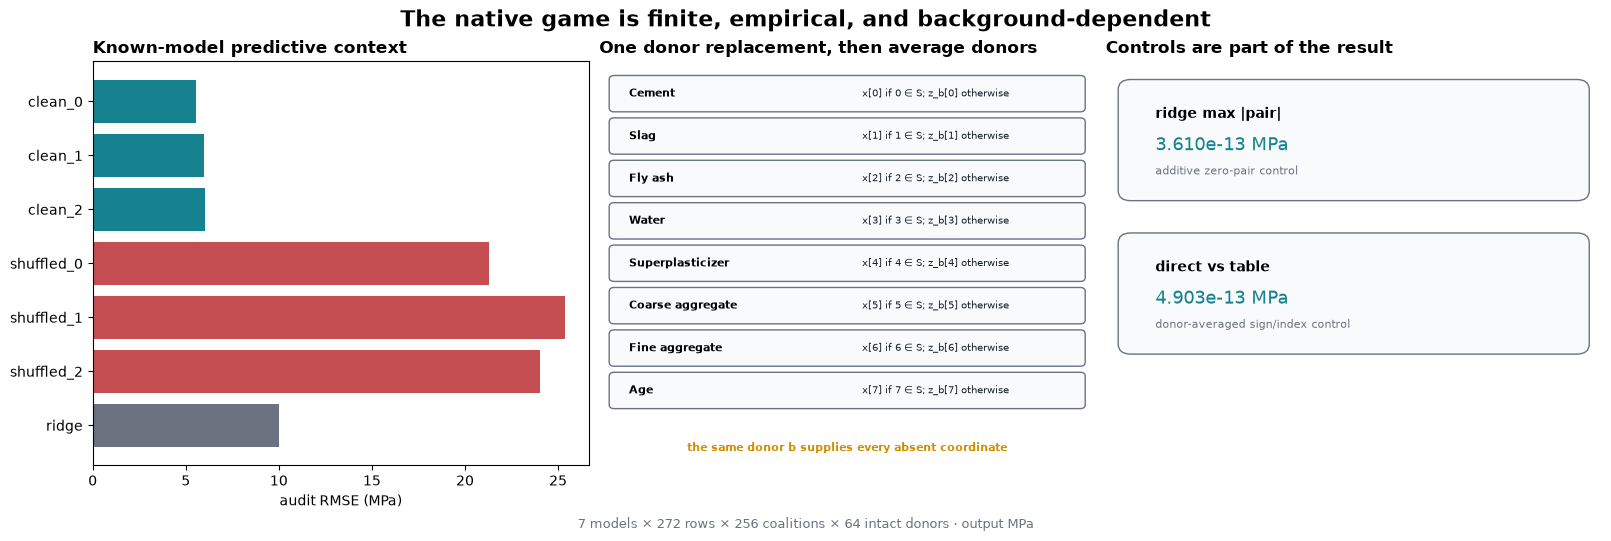

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/03_native_game_and_controls.png')

In [48]:
figure = plot_native_game_and_controls(evaluated)
show_figure(figure, "03_native_game_and_controls")


The clean predictors have much lower audit RMSE than their shuffled-label counterparts. The additive
ridge control has pair interactions near numerical zero, and independently rebuilt four-forward
synergies agree with table indexing. These checks establish that the model and game construction
behave as intended; they do not decide which interaction definition to prefer.

<details>
<summary>Interpretation - what does the shuffled-label control rule out?</summary>

A large pair coefficient alone is not evidence that a model learned useful structure. The shuffled
models can have large interactions while predicting strength poorly. Read predictive quality first,
then ask how each rule describes that particular fitted model.

</details>


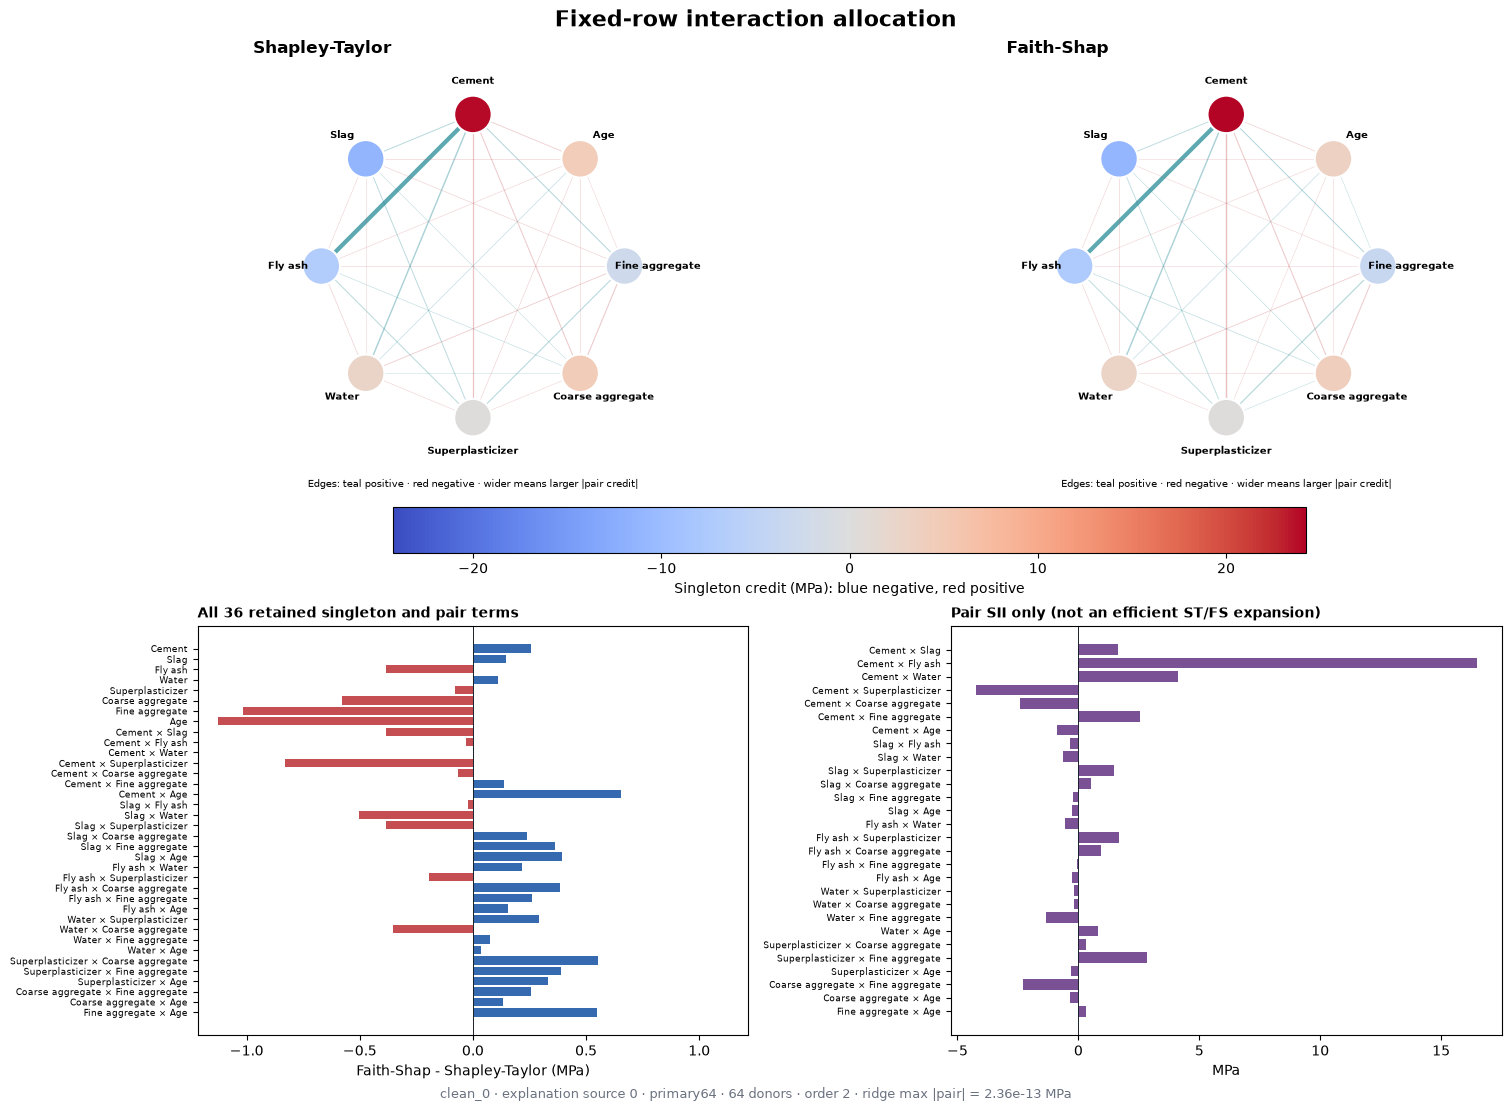

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/04_fixed_row_interaction_graph.png')

In [49]:
figure = plot_fixed_row_interaction_graph(play, prepared["feature_names"])
show_figure(figure, "04_fixed_row_interaction_graph")


Node color is singleton credit; edge color and width are signed and absolute pair credit. The two
methods share node positions and scales. A complete term-difference strip prevents graph thresholds
from silently hiding small or zero terms.


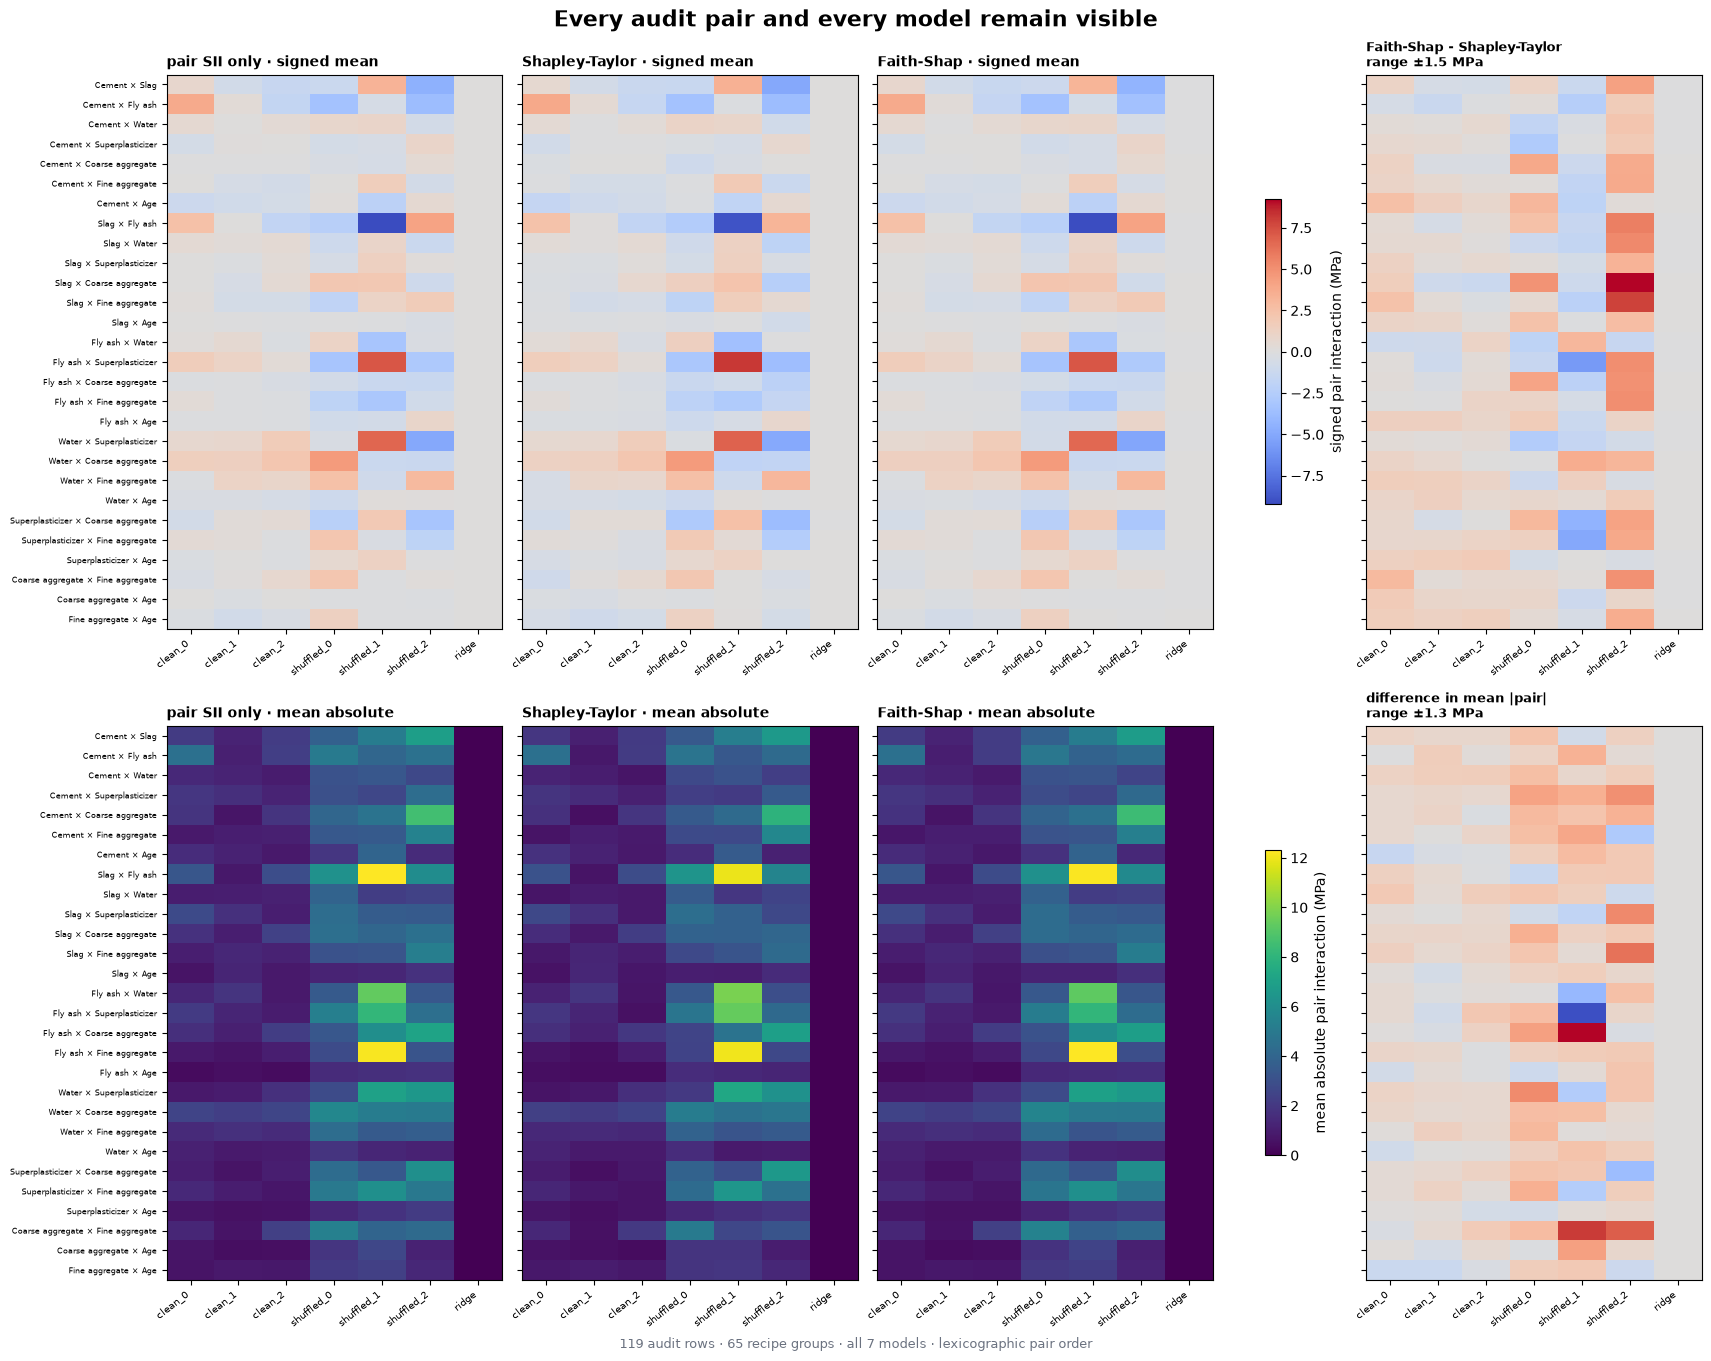

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/05_allrow_pair_heatmaps.png')

In [50]:
figure = plot_allrow_pair_heatmaps(evaluated, prepared["feature_names"])
show_figure(figure, "05_allrow_pair_heatmaps")


These matrices summarize all 119 audit rows by recipe group and preserve each model seed. Signed mean
and mean absolute magnitude are separate because cancellation is itself part of the interpretation.
SII is labeled `pair SII only`.


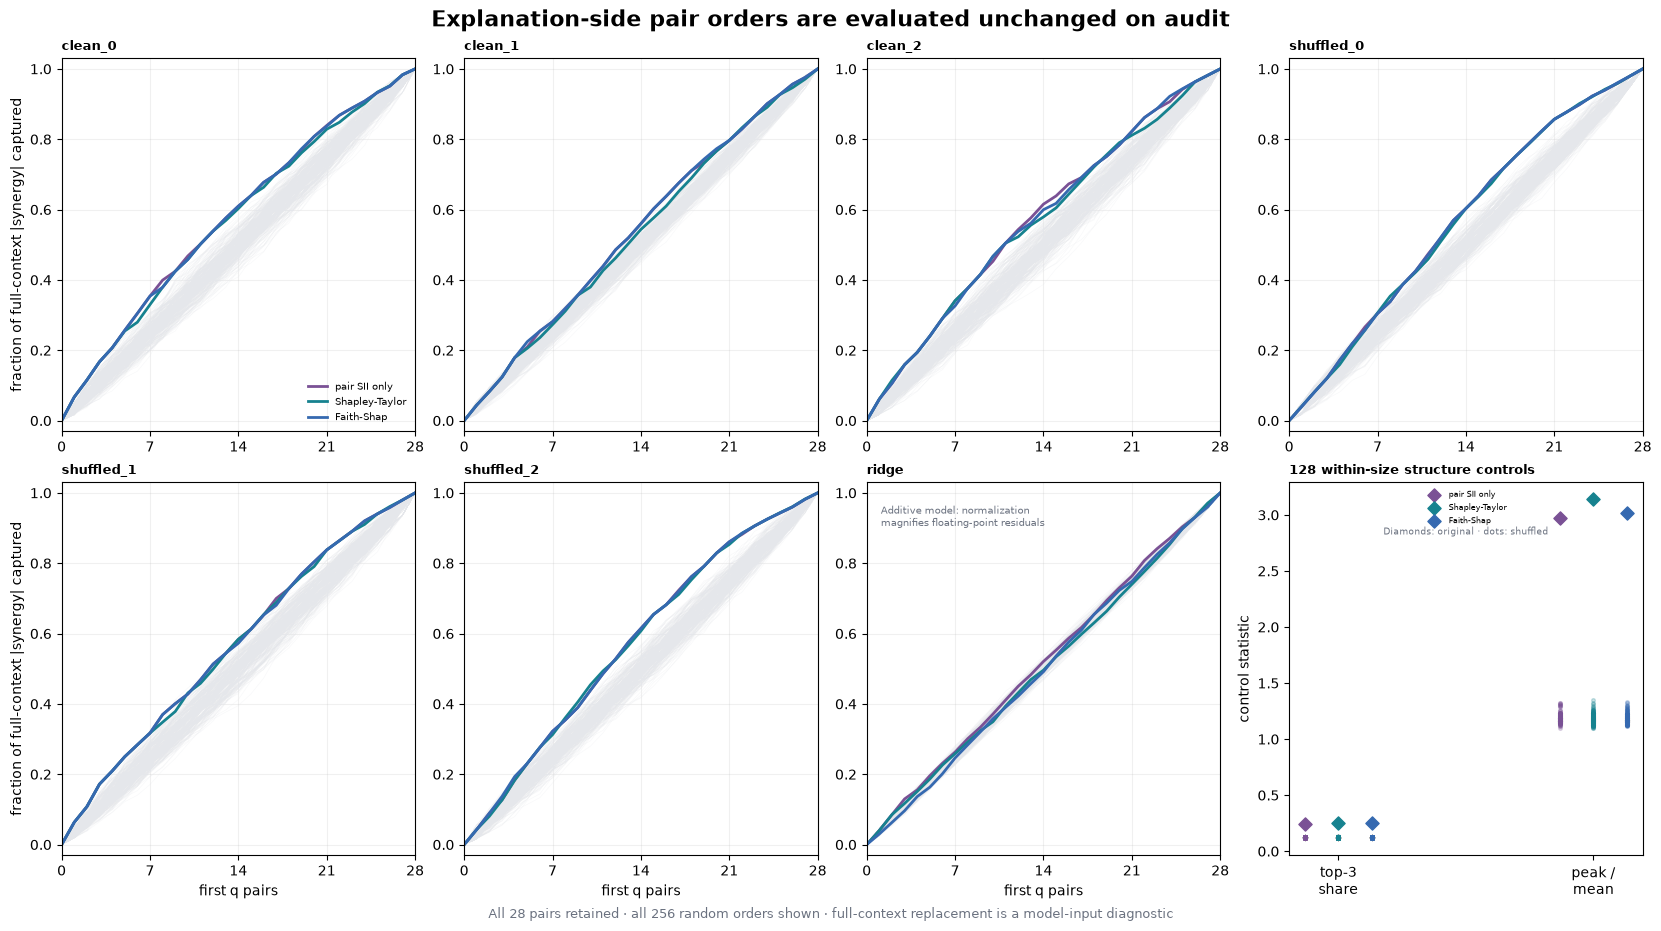

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/06_heldout_pair_order_capture.png')

In [51]:
figure = plot_heldout_pair_order_capture(evaluated, prepared["feature_names"])
show_figure(figure, "06_heldout_pair_order_capture")


Each complete pair order is learned on the 153 explanation rows, then carried unchanged to the 119
audit rows. The target is mean absolute full-context synergy under the declared model-input
replacement. All 256 random-order curves remain visible; this is not a causal validation or a
significance test. The three rule-specific curves can be close even when their signed coefficients
differ: ordering 28 pairs discards magnitude and sign information. In the ridge panel, normalizing
near-zero floating-point residuals produces a nontrivial-looking curve; its absolute interaction
scale is the relevant control. Diamonds in the final panel are the original clean model's statistics;
the dots are the 128 within-size shuffled games.

<details>
<summary>Interpretation - does a curve above random identify a causal circuit?</summary>

No. It means an explanation-side ranking concentrates a held-out model-input diagnostic more quickly
than random pair orderings. The target is the full-context second difference under intact donor
replacement. It is neither a causal intervention on physical concrete nor the defining objective of
any one interaction index. Compare the curve with the signed heatmaps and reconstruction plots.

</details>


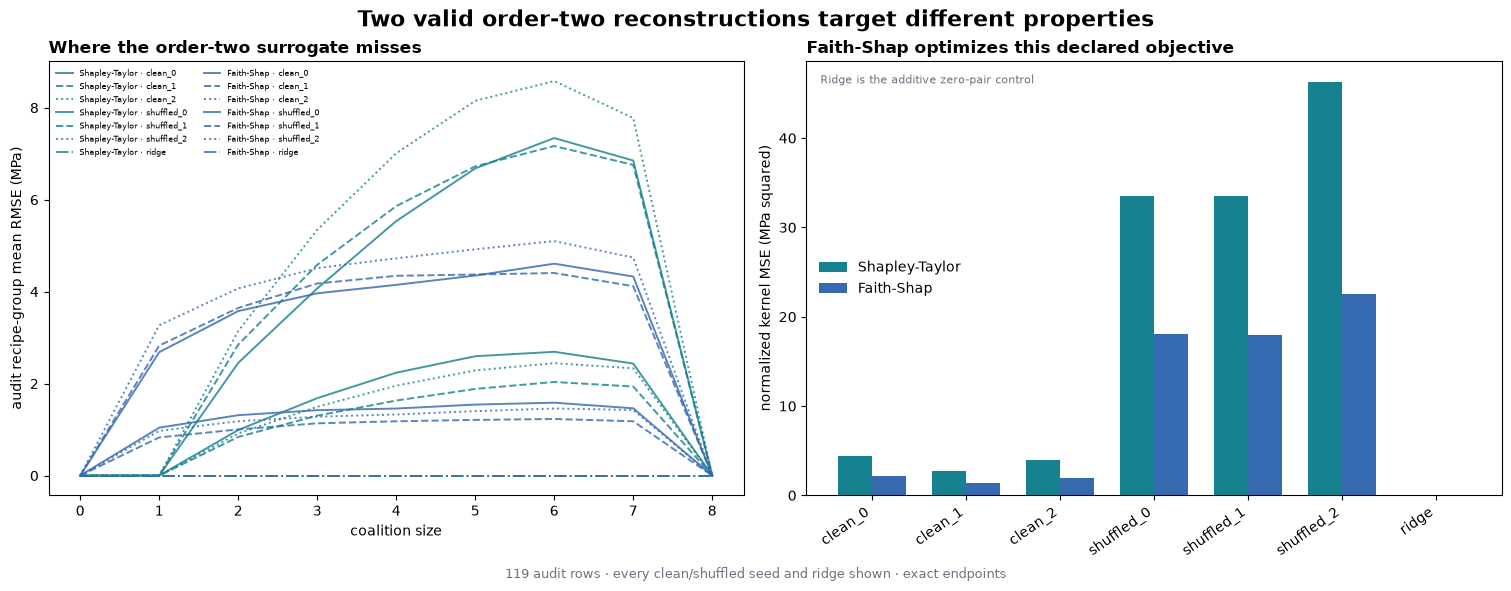

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/07_order_two_reconstruction.png')

In [52]:
figure = plot_order_two_reconstruction(evaluated)
show_figure(figure, "07_order_two_reconstruction")


Faith-Shap may be labeled the optimum for its normalized kernel error because that is its definition.
The coalition-size residuals show where each order-two reconstruction misses. Empty and full
constraints hold to float64 solver precision, and the degree-two and ridge controls should expose implementation drift.


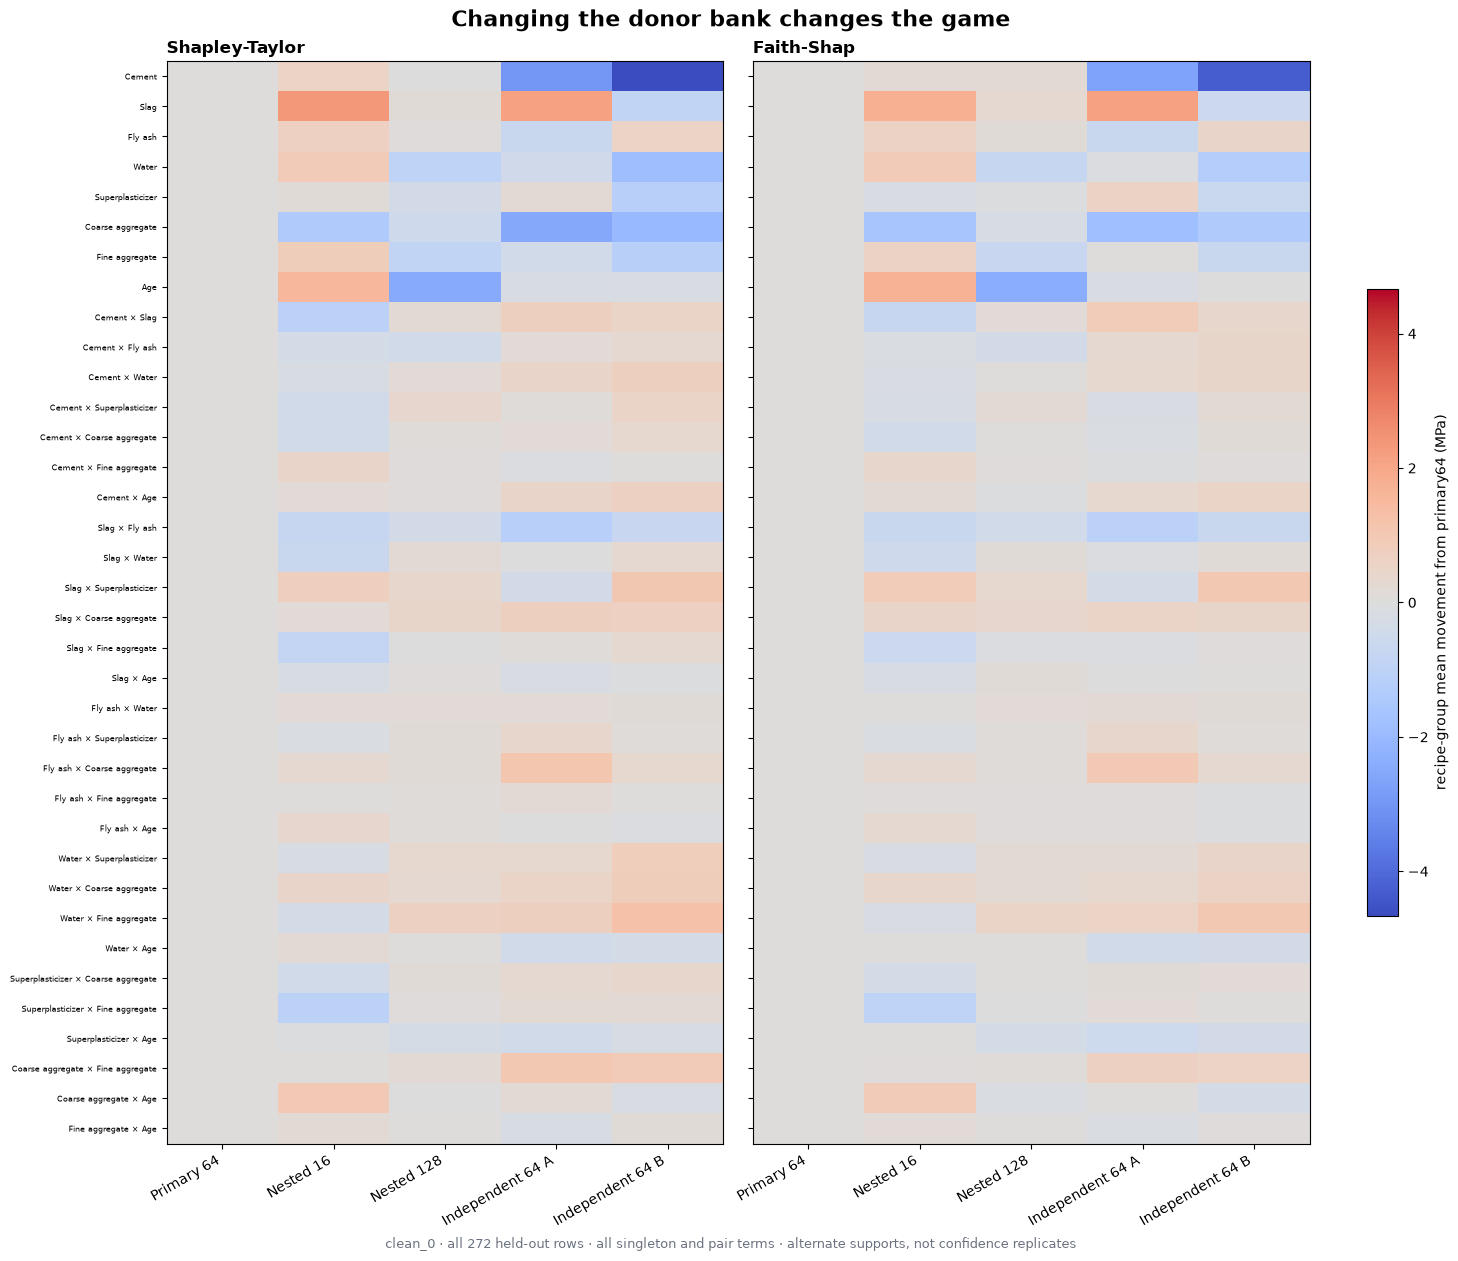

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/08_background_changes_the_game.png')

In [53]:
figure = plot_background_changes_the_game(evaluated, prepared["feature_names"])
show_figure(figure, "08_background_changes_the_game")


`nested16` and `nested128` are related prefixes; `independent64_a` and `independent64_b` are alternate
finite supports. Their spread is not a standard error. Moving the background changes the coalition
game before either interaction rule is applied.


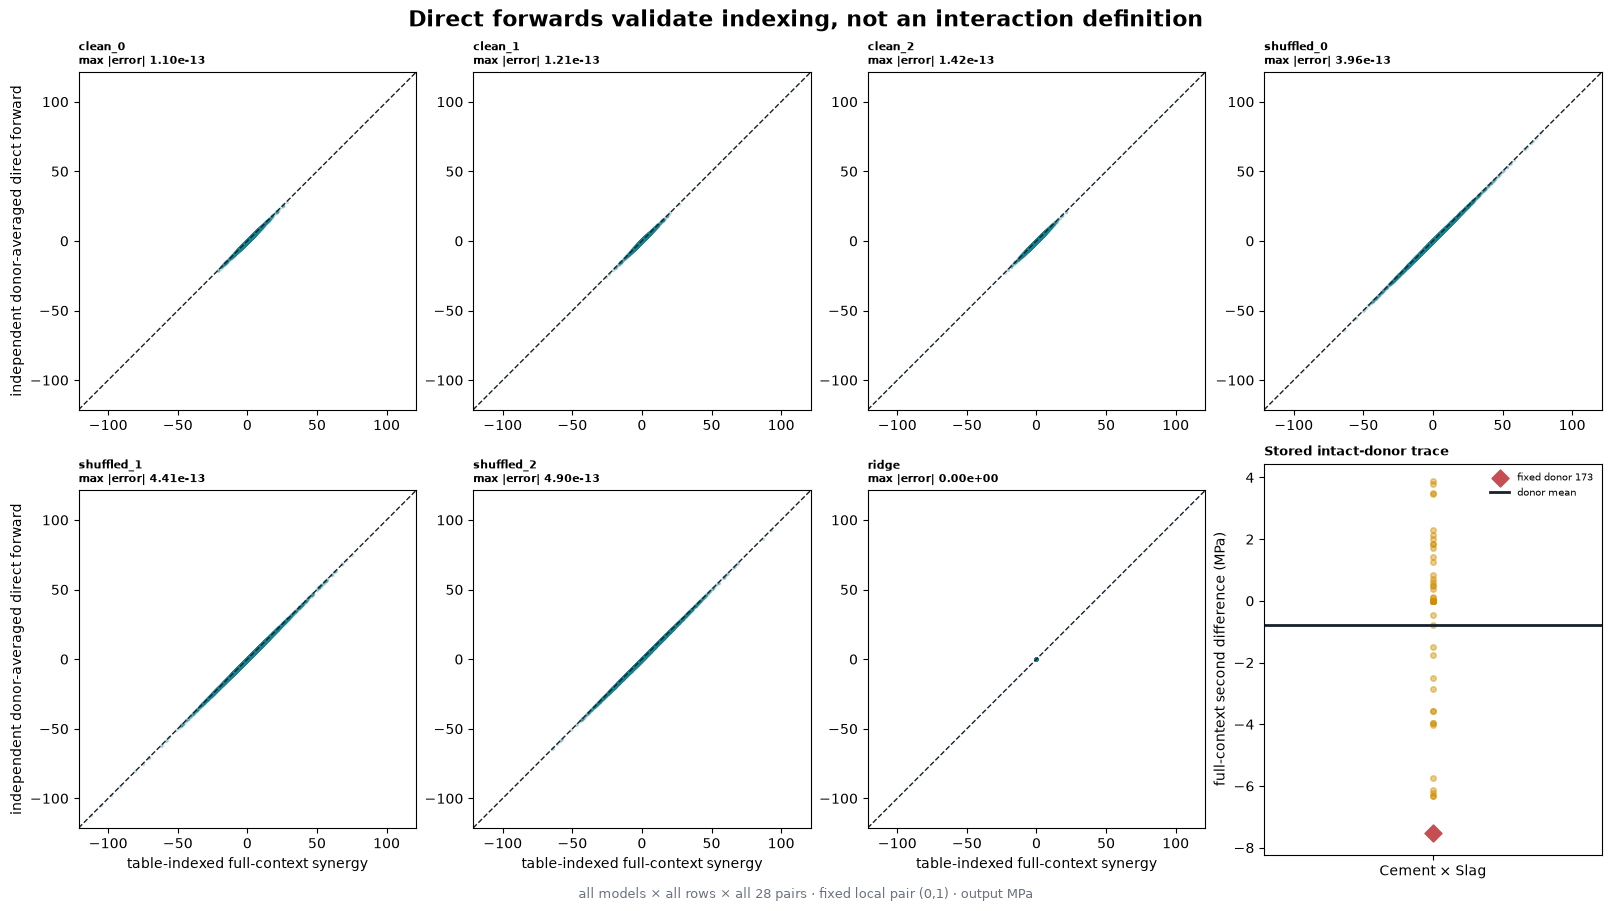

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/09_contextual_pair_interventions.png')

In [54]:
figure = plot_contextual_pair_interventions(
    evaluated, play, prepared["feature_names"]
)
show_figure(figure, "09_contextual_pair_interventions")


The direct-forward path rebuilds the four full-context inputs independently of table indexing. Its
agreement with the stored second difference checks mask order and sign. Shapley-Taylor, Faith-Shap,
and SII can still differ validly because they aggregate contexts differently.


## Try It Yourself: donor-context microscope

Edit the model, row, background, pair, context, or donor. `DONOR_SOURCE_ID=None` uses the whole
finite donor bank; choosing one donor constructs and clearly labels a different single-donor game.
Start with the predeclared explanation row. Audit rows are available only here, after every frozen
study figure has already been computed.


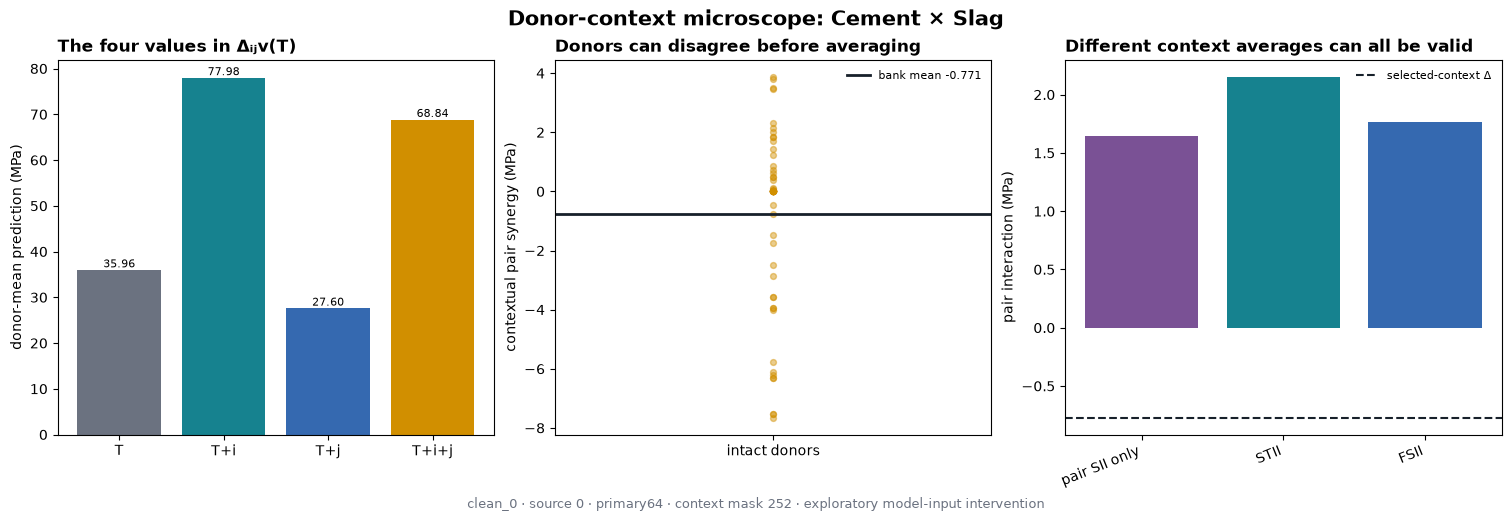

PosixPath('/home/bitwise/.cache/arena_extended/shapley_interactions/native-development-v8/figures/11_donor_context_play.png')

In [55]:
MODEL_KEY = "clean_0"
SOURCE_ID = 0
BACKGROUND_KEY = "primary64"
PAIR = (0, 1)
CONTEXT_MASK = 252
DONOR_SOURCE_ID = None

context_play = empirical_context_play(
    evaluated,
    methods=methods,
    model_key=MODEL_KEY,
    source_id=SOURCE_ID,
    background_key=BACKGROUND_KEY,
    pair=PAIR,
    context_mask=CONTEXT_MASK,
    donor_source_id=DONOR_SOURCE_ID,
)
figure = plot_donor_context_play(context_play, prepared["feature_names"])
show_figure(figure, "11_donor_context_play")


<details>
<summary>Ideas to try</summary>

1. Keep the row and pair fixed, but switch between `primary64`, its nested prefixes, and the two
   independent banks. Say explicitly that you changed the game.
2. Select donor `173`, then return to `None`. Compare the donor-specific second difference with the
   bank mean and look for signed cancellation.
3. Change `CONTEXT_MASK` while keeping it disjoint from `PAIR`. Compare the local derivative with
   each method's context aggregation.
4. Select an audit source ID only after the frozen study. The output should label this as exploratory
   audit reuse rather than a selected headline example.

</details>


# Conclusion

The pure four-way game answered the opening question with two coherent order-two allocations:
Shapley-Taylor kept lower-order dividends at zero and split the omitted term across pairs; Faith-Shap
moved both singleton and pair coefficients to improve a particular constrained reconstruction. SII
asked a third question by averaging pair derivatives over contexts.

On a real fitted-model game, the same distinctions remain:

- efficiency concerns the full-minus-empty ledger, not every interior coalition;
- faithfulness is specific to a kernel, degree, and exact constraints;
- a pair coefficient can include routed higher-order credit;
- a contextual second difference is one direct model-input intervention, not the unique pair index;
- changing the donor bank changes the explanation game; and
- exact enumeration costs $2^n$, so the eight-feature study does not solve scalable interaction
  discovery.

The Concrete outputs explain specified fitted predictors on finite empirical donor-replacement games
in MPa. They do not identify physical ingredient interactions or population causal effects.


## Further reading

- Sundararajan, Dhamdhere, and Agarwal, [*The Shapley Taylor Interaction
  Index*](https://proceedings.mlr.press/v119/sundararajan20a.html).
- Tsai, Yeh, and Ravikumar, [*Faith-Shap: The Faithful Shapley Interaction
  Index*](https://www.jmlr.org/papers/v24/22-0202.html).
- Section 16.3 for the exact Shapley Interaction Index convention used as the labeled comparator.
- Sections 16.14–16.15 for the known Concrete predictors, finite backgrounds, and attribution-game
  controls reused here.
